# Разведочный анализ nowcasting роста ВРП регионов России

Главная зависимая переменная индекс физического объема валового регионального продукта (ИФО ВРП) - это относительный статистический показатель, который отражает, как изменился реальный объем производства товаров и услуг в регионе по сравнению с предыдущим годом, исключая влияние изменения цен (инфляции).

Вопросы для EDA:

1. Как устроена цель (ИФО ВРП, г/г): сколько наблюдений, где пропуски, как склеены ОКВЭД-2007 и ОКВЭД2, какой разброс и что в нём от общих годовых шоков, а что от региона.
2. Какие признаки есть в обучающем окне, а какие появляются только к валидации или тесту.
3. Где в признаках нули, выбросы и разрывы методологии.
4. Какие месячные ряды после агрегации до года связаны с ростом ВРП, и держится ли эта связь при переходе от обучения к валидации.
5. Есть ли зависимости роста ВРП с другими признаками.

Предварительно период обучения - 2005-2016, период валидации - 2017-2021, период теста - 2022-2024.

Данные для панели были собраны в основном из двух источников: [ЦБ РФ](https://www.cbr.ru) и [ЕМИСС](https://www.fedstat.ru).

In [1]:
import pathlib
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

SEED = 42
rng = np.random.default_rng(SEED)

ROOT = pathlib.Path.cwd()
P = ROOT / "data/processed"
REF = ROOT / "data/reference"

TRAIN, VAL, TEST = (2005, 2016), (2017, 2021), (2022, 2024)

# Палитра: одна основная, один акцент, серый для фона
C_MAIN, C_ACC, C_GREY, C_SEC = "#2E5A87", "#D1495B", "#9AA5B1", "#E9A23B"
PERIOD_COL = {"обучение": "#2E5A87", "валидация": "#E9A23B", "тест": "#D1495B"}
plt.style.use("seaborn-v0_8-whitegrid")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})


def period_of(y):
    if TRAIN[0] <= y <= TRAIN[1]:
        return "обучение"
    if VAL[0] <= y <= VAL[1]:
        return "валидация"
    if TEST[0] <= y <= TEST[1]:
        return "тест"
    return "вне окна"


def shade_periods(ax, alpha=0.08):
    for (a, b), lab in [(TRAIN, "обучение"), (VAL, "валидация"), (TEST, "тест")]:
        ax.axvspan(a - 0.5, b + 0.5, color=PERIOD_COL[lab], alpha=alpha, lw=0)

## 1. Состав датасета

Загружаю все таблицы `data/processed/` и справочник регионов. Для каждой таблицы проверяю гранулярность, уникальность ключа и охват по времени.

In [2]:
reg = pd.read_csv(REF / "regions.csv")
geo = pd.read_csv(REF / "region_geo.csv")
adj = pd.read_csv(REF / "adjacency_long.csv")
cat = pd.read_csv(P / "feature_catalog.csv", sep=";")

S = reg[reg.in_sample].copy()
SAMPLE = set(S.region_id)
NAME = S.set_index("region_id").name_short.to_dict()
FD = S.set_index("region_id").fd.to_dict()

tables = {
    "features_regional_monthly_long": (["feature", "region_id", "year", "month"], "регион x месяц x признак"),
    "features_regional_annual_wide": (["region_id", "year"], "регион x год"),
    "features_national_monthly_wide": (["year", "month"], "месяц"),
    "features_national_annual_long": (["feature", "year"], "год x признак"),
    "target_grp_wide": (["region_id", "year"], "регион x год"),
}
D, rows = {}, []
for name, (key, grain) in tables.items():
    d = pd.read_parquet(P / f"{name}.parquet")
    D[name] = d
    n_feat = d.feature.nunique() if "feature" in d else d.shape[1] - len(key)
    rows.append({"таблица": name, "строк": len(d), "признаков": n_feat, "гранулярность": grain,
                 "дублей ключа": int(d.duplicated(key).sum()),
                 "годы": f"{int(d.year.min())}–{int(d.year.max())}",
                 "регионов": d.region_id.nunique() if "region_id" in d else "—"})
profile = pd.DataFrame(rows).set_index("таблица")
print(f"Единиц в выборке: {len(S)}, из них федеральных округов: {S.fd.nunique()}")
profile

Единиц в выборке: 85, из них федеральных округов: 8


,строк,признаков,гранулярность,дублей ключа,годы,регионов
таблица,,,,,,
features_regional_monthly_long,1689800,119,регион x месяц x признак,0,1999–2026,103
features_regional_annual_wide,3002,62,регион x год,0,1990–2025,85
features_national_monthly_wide,816,126,месяц,0,1960–2027,—
features_national_annual_long,24,2,год x признак,0,2002–2025,—
target_grp_wide,2314,38,регион x год,0,1997–2024,85


Ключи уникальны во всех пяти таблицах. Таблицы кроме основной выборки содержат строки РФ и федеральных округов, поэтому регионов в них больше 85; дальше я везде фильтрую по флагу `in_sample` только регионы РФ, без агрегации РФ и федеральных округов.

In [3]:
cat["family"] = cat.table
cat.groupby(["table", "group"]).size().rename("признаков").to_frame()

признаков
table            group                                             
national_annual  8. Ограничение для согласования                  2
national_monthly 1. Официальная месячная статистика (РФ)          6
                 2. Опросы                                        6
                 3. Финансы и кредит                             14
                 5. Сырьевые цены и отраслевые шоки              95
                 7. Календарь и шоки                              3
                 8. Ограничение для согласования                  2
regional_annual  1. Официальная статистика (год)                 17
                 6. Структурные признаки                         45
regional_monthly 1. Официальная месячная статистика              74
                 3. Финансы и кредит                             17
                 4. Бюджет и налоги                              28
target           Цель                                             2
                 Цель (multi-task)                               36

## 2. Целевая переменная

Цель в датасете лежит двумя рядами: `grp_okved1_yoy` (ОКВЭД-2007, 1997–2016) и `grp_yoy` (ОКВЭД2, 2017–2024). Они не пересекаются ни в одном году, поэтому склейка такая: до 2016 года беру первый ряд, с 2017 второй. Перевожу индекс в проценты прироста: `g = ИФО − 100`, единица измерения - процентные пункты.

In [4]:
T = D["target_grp_wide"].copy()
T["year"] = T.year.astype(int)
both = T[["grp_okved1_yoy", "grp_yoy"]].notna().all(axis=1).sum()
print("лет, где заполнены оба ряда:", both)

T["source"] = np.where(T.grp_yoy.notna(), "ОКВЭД2", np.where(T.grp_okved1_yoy.notna(), "ОКВЭД-2007", None))
T["ifo"] = T.grp_yoy.fillna(T.grp_okved1_yoy)

zeros = T[T.region_id.isin(SAMPLE) & (T.ifo == 0)]
print("\nнулевых значений ИФО ВРП в выборке:", len(zeros))
print(zeros.assign(name=zeros.region_id.map(NAME)).groupby("name").year.agg(["min", "max", "count"]))

лет, где заполнены оба ряда: 0

нулевых значений ИФО ВРП в выборке: 21
                             min   max  count
name                                         
Ненецкий АО                 1997  2000      4
Ханты-Мансийский АО - Югра  1997  2000      4
Чеченская Республика        1997  2005      9
Ямало-Ненецкий АО           1997  2000      4


Ноль в индексе физического объёма - это пропуск, записанный в источнике (ЕМИСС) нулём. Нули стоят у четырёх автономных округов за 1997–2000 годы (тогда Росстат не выделял их из областей) и у Чечни за 1997–2005 годы. 2005 год Чечни попадает в обучающее окно, так что без замены на пропуск модель получила бы падение ВРП на 100%. Заменяю нули на NaN.

Пропуски цели с 2005 года:
name
Чеченская Республика    2005


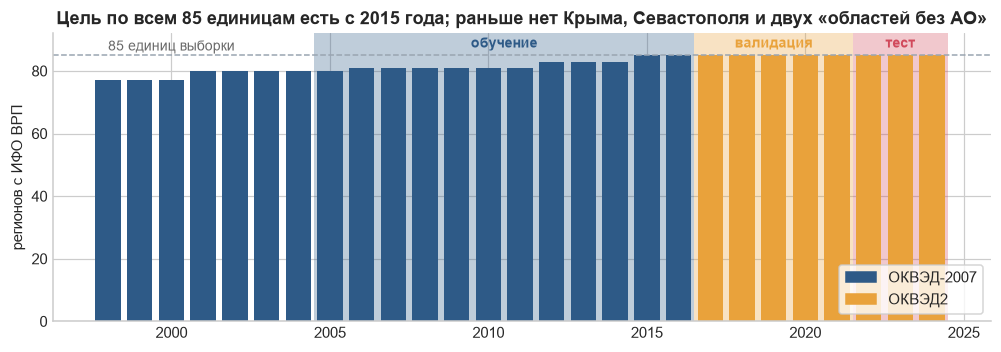

In [5]:
T.loc[T.ifo == 0, "ifo"] = np.nan
T["g"] = T.ifo - 100
TS = T[T.region_id.isin(SAMPLE)].copy()
TS["name"] = TS.region_id.map(NAME)
TS["fd"] = TS.region_id.map(FD)
TS["period"] = TS.year.map(period_of)

cov = TS[TS.year >= 1998].groupby("year").agg(регионов=("g", "count"), источник=("source", "first"))
missing = (TS[(TS.year >= TRAIN[0]) & TS.g.isna()]
           .groupby("name").year.apply(lambda s: f"{s.min()}–{s.max()}" if s.min() != s.max() else str(s.min())))
print("Пропуски цели с 2005 года:")
print(missing.to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
shade_periods(ax, 0.3)
ax.bar(cov.index, cov["регионов"], color=[C_MAIN if s == "ОКВЭД-2007" else C_SEC for s in cov["источник"]])
ax.axhline(85, color=C_GREY, ls="--", lw=1)
for (a, b), lab in [(TRAIN, "обучение"), (VAL, "валидация"), (TEST, "тест")]:
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.98, lab, ha="center", color=PERIOD_COL[lab], fontsize=9, fontweight="bold")
ax.text(1998, 86.5, "85 единиц выборки", color="dimgray", fontsize=9)
ax.set_ylim(0, 92)
ax.set_title("Цель по всем 85 единицам есть с 2015 года; раньше нет Крыма, Севастополя и двух «областей без АО»")
ax.set_ylabel("регионов с ИФО ВРП")
ax.legend(handles=[mpl.patches.Patch(color=C_MAIN, label="ОКВЭД-2007"), mpl.patches.Patch(color=C_SEC, label="ОКВЭД2")],
          loc="lower right", frameon=True)
plt.show()

С 2005 года цель есть у 80–85 единиц из 85. Все пропуски объясняются составом выборки, а не качеством данных: Крым и Севастополь появляются в 2015 году, Тюменская область без ХМАО и ЯНАО и Архангельская область без НАО в 2012 году, у Чечни нет 2005 года (в источнике - ноль). В обучающем окне 985 наблюдений «регион-год».

Панель несбалансированная, и это надо учесть в моделях: модели с фиксированными эффектами региона должны принимать пропуски, а не выбрасывать регион целиком.

### 2.1. Динамика и разброс по годам

График показывает, как распределён рост ВРП по регионам в каждом году: медиана, межквартильный размах и 10–90 перцентили. Для сравнения изображен рост ВВП России и ряд ИФО ВРП для РФ в целом из того же источника.

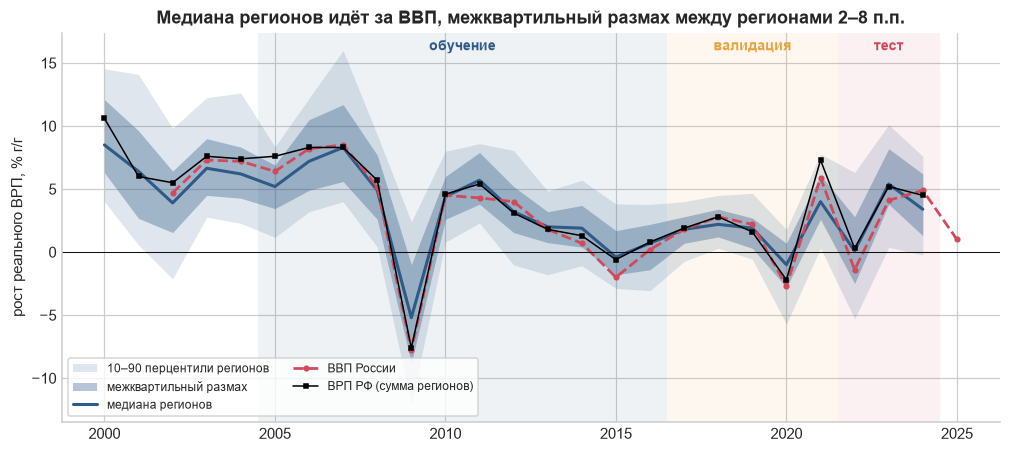

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
медиана,5.20,7.20,8.30,4.90,-5.20,4.40,5.70,3.20,2.00,1.90,-0.40,0.70,1.80,2.20,1.90,-1.00,4.00,0.10,5.40,3.40
std,3.67,3.50,5.35,4.49,6.73,4.26,3.54,3.72,4.06,3.85,2.91,2.82,2.49,2.61,2.38,3.25,3.62,4.59,4.61,4.24
IQR,3.45,5.60,6.10,5.10,7.80,3.40,4.10,3.65,2.45,3.30,3.50,3.60,2.10,2.20,2.40,3.50,3.50,5.30,4.40,4.90
n,80.00,81.00,81.00,81.00,81.00,81.00,81.00,83.00,83.00,83.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00
ВВП,6.40,8.20,8.50,5.20,-7.80,4.50,4.30,4.00,1.80,0.70,-2.00,0.20,1.80,2.80,2.20,-2.70,5.90,-1.40,4.10,4.90
ВРП РФ,7.60,8.30,8.30,5.70,-7.60,4.60,5.40,3.10,1.80,1.30,-0.60,0.80,1.90,2.80,1.60,-2.20,7.30,0.30,5.20,4.50


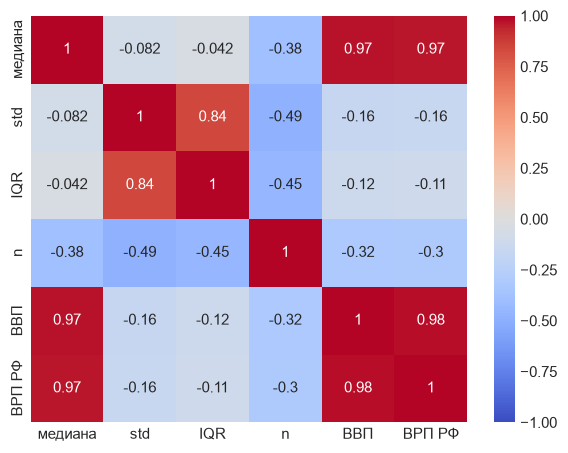

In [6]:
gdp = (D["features_national_annual_long"].pivot(index="year", columns="feature", values="value"))
gdp.index = gdp.index.astype(int)
gdp_g = gdp.gdp_yoy_y.fillna(gdp.gdp_old_yoy_y) - 100

tl = pd.read_parquet(P / "target_grp_long.parquet")
tl = tl[tl.feature.isin(["grp_yoy", "grp_okved1_yoy"]) & tl.region_id.str.startswith("rossiyskaya_federatsiya")]
tl = tl.assign(year=tl.year.astype(int)).pivot_table(index="year", columns="region_id", values="value")
# с 2023 года Росстат даёт строку «РФ без учёта новых субъектов»
rf_grp = tl["rossiyskaya_federatsiya"].fillna(tl["rossiyskaya_federatsiya_bez_ucheta_novykh_subektov_s_01_01_2023"]) - 100

q = TS[TS.year >= 2000].groupby("year").g.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
fig, ax = plt.subplots(figsize=(11, 4.6))
shade_periods(ax)
ax.fill_between(q.index, q[0.1], q[0.9], color=C_MAIN, alpha=0.15, lw=0, label="10–90 перцентили регионов")
ax.fill_between(q.index, q[0.25], q[0.75], color=C_MAIN, alpha=0.35, lw=0, label="межквартильный размах")
ax.plot(q.index, q[0.5], color=C_MAIN, lw=2, label="медиана регионов")
ax.plot(gdp_g.loc[2000:].index, gdp_g.loc[2000:], color=C_ACC, lw=1.8, ls="--", marker="o", ms=3, label="ВВП России")
ax.plot(rf_grp.loc[2000:].index, rf_grp.loc[2000:], color="black", lw=1, marker="s", ms=3, label="ВРП РФ (сумма регионов)")
ax.axhline(0, color="black", lw=0.6)
for (a, b), lab in [(TRAIN, "обучение"), (VAL, "валидация"), (TEST, "тест")]:
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.92, lab, ha="center", color=PERIOD_COL[lab], fontsize=9, fontweight="bold")
ax.set_ylabel("рост реального ВРП, % г/г")
ax.set_title("Медиана регионов идёт за ВВП, межквартильный размах между регионами 2–8 п.п.")
ax.legend(loc="lower left", fontsize=8, ncol=2, frameon=True)
plt.show()

disp = TS[TS.year >= 2005].groupby("year").g.agg(медиана="median", std="std", IQR=lambda s: s.quantile(.75) - s.quantile(.25), n="count")
disp["ВВП"] = gdp_g
disp["ВРП РФ"] = rf_grp
display(disp.T)
sns.heatmap(disp.corr(numeric_only=True), vmax=1, vmin=-1, cmap='coolwarm', annot=True)
plt.show()

Медиана регионов идёт за ВВП почти год в год (корреляция 0,97). Межрегиональный разброс в годы без шоков держится около 2,4–2,6 п.п. (стандартное отклонение, 2017–2019), а в кризисы растёт: 6,7 п.п. в 2009 году, 4,6 п.п. в 2022–2023 годах. Значит, ошибка любой модели будет выше как раз в этих годах.

Для вопроса EDA 1 важна еще одна деталь. Рост ВРП РФ (сумма регионов) расходится с ВВП больше всего в переломные годы. В 2015 и 2022 годах сумма ВРП упала слабее ВВП на 1,4 и 1,7 п.п., в 2021 году выросла сильнее на 1,4 п.п. Во всех четырёх годах спада (2009, 2015, 2020, 2022) ВРП падал слабее. Поэтому нельзя ставить как равенство ВРП РФ и ВВП, для предсказания ВВП разницу «ВРП минус ВВП» придётся моделировать отдельно.

### 2.2. Распределение цели по периодам

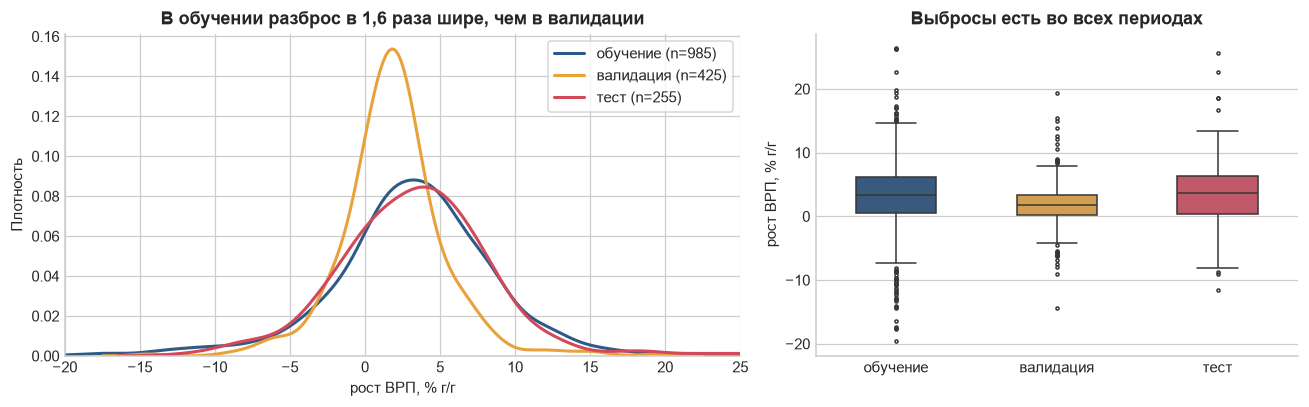

,n,mean,std,median,p1,p99,skew,kurt
period,,,,,,,,
обучение,985,3.24,5.44,3.40,-12.92,16.33,-0.25,2.33
валидация,425,1.85,3.43,1.80,-6.76,12.48,0.34,4.01
тест,255,3.38,5.03,3.60,-8.42,18.60,0.46,2.20


In [7]:
desc = (TS[TS.year.between(TRAIN[0], TEST[1])].groupby("period").g
        .agg(n="count", mean="mean", std="std", median="median",
             p1=lambda s: s.quantile(.01), p99=lambda s: s.quantile(.99),
             skew=lambda s: stats.skew(s.dropna()), kurt=lambda s: stats.kurtosis(s.dropna()))
        .reindex(["обучение", "валидация", "тест"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
for lab in ["обучение", "валидация", "тест"]:
    s = TS.loc[TS.period == lab, "g"].dropna()
    sns.kdeplot(s, ax=axes[0], color=PERIOD_COL[lab], lw=2, label=f"{lab} (n={len(s)})", clip=(-30, 40))
axes[0].set_xlim(-20, 25)
axes[0].set_xlabel("рост ВРП, % г/г")
axes[0].set_ylabel("Плотность")
axes[0].set_title("В обучении разброс в 1,6 раза шире, чем в валидации")
axes[0].legend(frameon=True)
sub = TS[TS.year.between(TRAIN[0], TEST[1])]
sns.boxplot(data=sub, x="period", y="g", order=["обучение", "валидация", "тест"], palette=PERIOD_COL,
            ax=axes[1], fliersize=2, width=0.5)
axes[1].set_xlabel("")
axes[1].set_ylabel("рост ВРП, % г/г")
axes[1].set_title("Выбросы есть во всех периодах")
plt.tight_layout()
plt.show()
desc

In [8]:
tv = TS[TS.year.between(TRAIN[0], VAL[1])].copy()
tv["dev"] = tv.g - tv.groupby("year").g.transform("median")
print("Самые большие отклонения от медианы своего года (обучение и валидация)")
tv.reindex(tv.dev.abs().sort_values(ascending=False).index)[["name", "year", "g", "dev", "source"]].head(15)

Самые большие отклонения от медианы своего года (обучение и валидация)


,name,year,g,dev,source
959,Ненецкий АО,2009,22.60,27.80,ОКВЭД-2007
222,Чукотский автономный округ,2010,-17.30,-21.70,ОКВЭД-2007
217,Чукотский автономный округ,2005,-14.40,-19.60,ОКВЭД-2007
281,Еврейская автономная область,2013,-17.50,-19.50,ОКВЭД-2007
221,Чукотский автономный округ,2009,13.40,18.60,ОКВЭД-2007
2051,Тюменская область без ХМАО и ЯНАО,2014,-16.50,-18.40,ОКВЭД-2007
958,Ненецкий АО,2008,-13.30,-18.20,ОКВЭД-2007
163,Чеченская Республика,2007,26.40,18.10,ОКВЭД-2007
1779,Сахалинская область,2007,26.30,18.00,ОКВЭД-2007
1405,Республика Ингушетия,2007,26.30,18.00,ОКВЭД-2007


В обучении стандартное отклонение роста 5,4 п.п., в валидации 3,4, в тесте 5. Распределение почти симметричное, но хвосты тяжелее нормальных (эксцесс 2–4). Крупнейшие отклонения от медианы года дают малые экономики с одним-двумя проектами: Ненецкий АО (+27,8 п.п. в 2009 году), Чукотка, Еврейская АО, Сахалин, Ингушетия и Чечня в 2007 году. Есть и Санкт-Петербург в 2021 году (+15,4 п.п. к медиане).

В RMSE без весов такие регионы весят столько же, сколько Москва, и могут перекрыть всё остальное. Поэтому обе версии метрики (без весов и с весами по размеру ВРП) обязательны, а при обучении нужно попробовать робастную функцию потерь и сравнить с MSE на валидации.

### 2.3. Что в разбросе от года, а что от региона

Если большая часть дисперсии роста ВРП приходится на общий годовой шок, то главная работа модели будет в том, чтобы предсказать годовой показатель (если делаем backcasting на период t-1, то ВВП для этого периода есть). Если на регион, то важны региональные признаки.

Раскладываю разброс в три пункта.

1. **Год.** Из роста каждого региона вычитаю средний рост всех регионов в этом году. Насколько уменьшилась сумма квадратов отклонений, такую долю разброса и объясняет год.
2. **Регион.** Для каждого региона считаю, на сколько в среднем за все годы окна он рос быстрее или медленнее среднего по своему году. Доля разброса, которую дают эти средние, и есть вклад постоянных различий между регионами.
3. **Остаток.** Всё остальное это отклонение конкретного региона в конкретном году.

Но даже если регионы ничем не отличаются, их средние за 5–12 лет случайно получатся разными. Чтобы понять, сколько даёт случайность, перемешиваю метки регионов внутри каждого года 500 раз и пересчитываю шаг 2. Настоящий вклад региона равен разнице между реальной долей и средней долей на перемешанных данных.

,обучение 2005–2016,валидация 2017–2021
год,0.412,0.285
регион (как посчитано),0.084,0.201
регион при перемешанных метках,0.050,0.144
регион сверх случайности,0.034,0.057
остаток,0.504,0.513
p (доля перемешиваний ≥ реальной),0.000,0.006
наблюдений,985,425


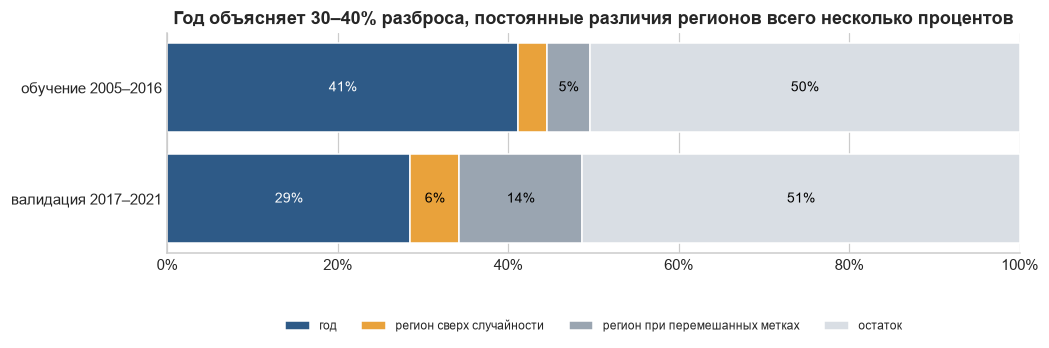

Среднее отклонение региона от своего года, 85 регионов: corr(обучение, валидация) = 0.26


In [9]:
def var_share(df, n_perm=500, seed=SEED):
    """Классификация разброса роста ВРП: год, затем регион, затем остаток."""
    d = df.dropna(subset=["g"]).copy()
    total = ((d.g - d.g.mean()) ** 2).sum()

    # вычитаем средний рост регионов в этом году
    d["dev"] = d.g - d.groupby("year").g.transform("mean")
    year_share = 1 - (d.dev ** 2).sum() / total

    # среднее отклонение региона от своего года за все годы окна
    region_share = (d.groupby("region_id").dev.transform("mean") ** 2).sum() / total

    # перемешиваем метки регионов внутри каждого года
    r = np.random.default_rng(seed)
    fake = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = d.groupby("year").region_id.transform(lambda s: r.permutation(s.values))
        fake[i] = (d.dev.groupby(shuffled).transform("mean") ** 2).sum() / total

    return pd.Series({
        "год": year_share,
        "регион (как посчитано)": region_share,
        "регион при перемешанных метках": fake.mean(),
        "регион сверх случайности": region_share - fake.mean(),
        "остаток": 1 - year_share - region_share,
        "p (доля перемешиваний ≥ реальной)": (fake >= region_share).mean(),
        "наблюдений": len(d)})


vs = pd.DataFrame({lab: var_share(TS[TS.year.between(a, b)]) for lab, (a, b) in
                   [("обучение 2005–2016", TRAIN), ("валидация 2017–2021", VAL)]})
display(vs.style.format("{:.3f}").format("{:.0f}", subset=pd.IndexSlice[["наблюдений"], :]))


fig, ax = plt.subplots(figsize=(10, 2.6))
parts = [("год", C_MAIN), ("регион сверх случайности", C_SEC),
         ("регион при перемешанных метках", C_GREY), ("остаток", "#D9DEE4")]
for j, col in enumerate(vs.columns):
    left = 0
    for name, color in parts:
        w = vs.loc[name, col] if name != "остаток" else vs.loc["остаток", col]
        ax.barh(j, w, left=left, color=color, edgecolor="white",
                label=(name if j == 0 else None))
        if w > 0.04:
            ax.text(left + w / 2, j, f"{w:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if color in (C_MAIN,) else "black")
        left += w
ax.set_yticks(range(len(vs.columns)))
ax.set_yticklabels(vs.columns)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title("Год объясняет 30–40% разброса, постоянные различия регионов всего несколько процентов")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4, fontsize=8, frameon=False)
plt.show()


def region_dev(a, b):
    x = TS[TS.year.between(a, b)].dropna(subset=["g"])
    return (x.g - x.groupby("year").g.transform("mean")).groupby(x.region_id).mean()

rd = pd.DataFrame({"обучение": region_dev(*TRAIN), "валидация": region_dev(*VAL)}).dropna()
print(f"Среднее отклонение региона от своего года, {len(rd)} регионов: "
      f"corr(обучение, валидация) = {rd.corr().iloc[0, 1]:.2f}")

In [10]:
# коррелирует ли отклонение региона от медианы года с прошлогодним значением
tv = TS[TS.year.between(TRAIN[0] - 1, VAL[1])].sort_values(["region_id", "year"]).copy()
tv["dev"] = tv.g - tv.groupby("year").g.transform("median")
tv["dev_lag"] = tv.groupby("region_id").dev.shift(1)
tv["g_lag"] = tv.groupby("region_id").g.shift(1)
pers = []
for lab, (a, b) in [("обучение", TRAIN), ("валидация", VAL)]:
    x = tv[tv.year.between(a, b)].dropna(subset=["dev", "dev_lag"])
    pers.append({"период": lab, "corr(g, g_{t-1})": x[["g", "g_lag"]].corr().iloc[0, 1],
                 "corr(откл., откл._{t-1})": x[["dev", "dev_lag"]].corr().iloc[0, 1]})
pd.DataFrame(pers).set_index("период")

,"corr(g, g_{t-1})","corr(откл., откл._{t-1})"
период,,
обучение,0.21,0.14
валидация,-0.04,0.16


Год объясняет 41% разброса роста ВРП на обучении и 29% на валидации. Это главная составляющая роста ВРП.

Постоянные различия между регионами дают сырыми 8% и 20%, но большую часть этого даёт случайность: при перемешанных метках получается 5% и 14%. Сверх случайности остаётся около 3% на обучении и 6% на валидации. Эффект маленький, но значимый.

Различия регионов к тому же плохо держатся во времени. Корреляция среднего отклонения региона на обучении и на валидации всего 0,26. Вывод: эффекты регионов не выбрасывать, но сжимать к нулю с помощью случайных эффектов или l2-регуляризации и переоценивать на расширяющемся окне.

Остаток, около половины разброса, приходится на отклонения конкретного региона в конкретном году. Они почти не переносятся на следующий год: корреляция с прошлогодним отклонением 0,14–0,16. Годовую компоненту за год t-1 даёт опубликованный ВВП за год t-1, но при nowcasting года t её саму надо оценивать по квартальному ВВП и национальным месячным рядам. Отклонение региона от общего роста по его прошлому не предсказать, его можно взять только из региональных данных текущего года.

### 2.4. Карта «регион x год»

Цвет показывает отклонение роста региона от медианы своего года. Регионы упорядочены по федеральным округам, годы с 2005 по 2024.

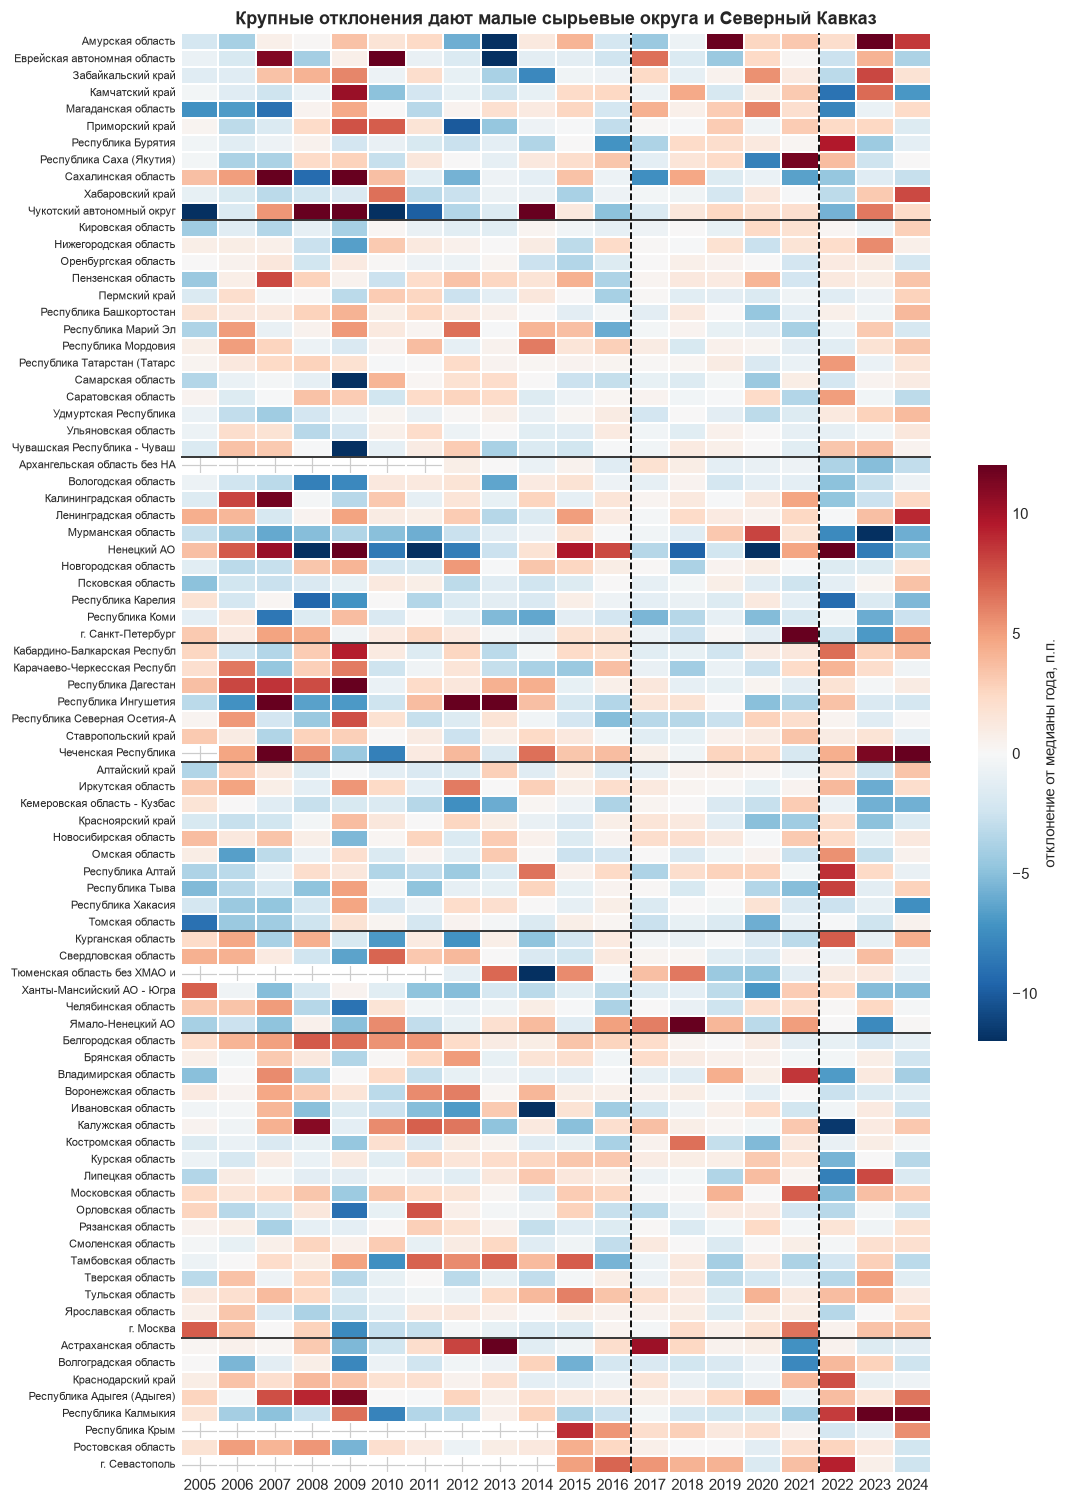

In [11]:
hm = TS[TS.year.between(2005, 2024)].copy()
hm["dev"] = hm.g - hm.groupby("year").g.transform("median")
order = S.sort_values(["fd", "name_short"]).region_id
piv = hm.pivot(index="region_id", columns="year", values="dev").reindex(order)
piv.index = [f"{NAME[r][:28]}" for r in piv.index]

fig, ax = plt.subplots(figsize=(11, 17))
sns.heatmap(piv, cmap="RdBu_r", center=0, vmin=-12, vmax=12, ax=ax,
            cbar_kws={"label": "отклонение от медианы года, п.п.", "shrink": 0.4}, linewidths=0.2, linecolor="white")
fd_sorted = S.sort_values(["fd", "name_short"]).fd.values
for i in range(1, len(fd_sorted)):
    if fd_sorted[i] != fd_sorted[i - 1]:
        ax.axhline(i, color="black", lw=1)
for x in [TRAIN[1] - 2004, VAL[1] - 2004]:
    ax.axvline(x, color="black", lw=1.2, ls="--")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7)
ax.set_title("Крупные отклонения дают малые сырьевые округа и Северный Кавказ")
plt.show()

In [12]:
vol = (TS[TS.year.between(TRAIN[0], VAL[1])].assign(dev=lambda d: d.g - d.groupby("year").g.transform("median"))
       .groupby("name").dev.agg(["std", "mean", "count"]).sort_values("std", ascending=False))
print("Самые волатильные регионы (std отклонения от медианы года, 2005–2021):")
print(vol.head(12).to_string())
print("\nСамые стабильные:")
print(vol.tail(6).to_string())

Самые волатильные регионы (std отклонения от медианы года, 2005–2021):
                                    std  mean  count
name                                                
Ненецкий АО                       11.68 -0.60     17
Чукотский автономный округ        10.34 -0.36     17
Тюменская область без ХМАО и ЯНАО  7.54 -0.77     10
Сахалинская область                7.36  1.14     17
Республика Ингушетия               7.32  0.71     17
Еврейская автономная область       6.92 -0.39     17
Чеченская Республика               5.74  2.25     16
Астраханская область               5.27  1.64     17
Амурская область                   5.23 -0.04     17
Ямало-Ненецкий АО                  4.92  1.16     17
Тамбовская область                 4.55  1.13     17
Республика Дагестан                4.38  3.05     17

Самые стабильные:
                                  std  mean  count
name                                              
Псковская область                1.58 -1.41     17
Ульяновская обл

Самые волатильные единицы: Ненецкий АО (стандартное отклонение от медианы года 11,7 п.п.), Чукотка (10,3), Тюменская область (7,5), Сахалин (7,4), Ингушетия (7,3), Еврейская АО (6,9). Самые ровные: Архангельская область (1,1), Татарстан (1,2), Удмуртия (1,5).

### 2.5. Наивные бенчмарки на валидации

Перед моделями полезно знать, какую ошибку дают самые простые правила, можно проанализировать ориентир для шкалы RMSE. Считаю только на валидации 2017–2021.

Рост ВРП каждого региона равен:
- «ВВП»: росту ВВП России за год.
- «Прошлый год»: рост региона как в t−1.
- «Среднее региона»: средний рост региона на обучающем окне.
- «ВВП + сдвиг региона»: ВВП плюс среднее отклонение региона от ВВП на обучении.

In [13]:
v = TS[TS.year.between(*VAL)].copy()
v["gdp"] = v.year.map(gdp_g)
tr = TS[TS.year.between(*TRAIN)].copy()
tr["gdp"] = tr.year.map(gdp_g)
reg_mean = tr.groupby("region_id").g.mean()
reg_shift = (tr.g - tr.gdp).groupby(tr.region_id).mean()
lag = TS.set_index(["region_id", "year"]).g
v["lag"] = [lag.get((r, y - 1), np.nan) for r, y in zip(v.region_id, v.year)]
bench = {"ВВП": v.gdp, "прошлый год": v.lag, "среднее региона (обучение)": v.region_id.map(reg_mean),
         "ВВП + сдвиг региона": v.gdp + v.region_id.map(reg_shift)}
rmse = lambda e: float(np.sqrt(np.nanmean(e ** 2)))
bt = pd.DataFrame({k: {"RMSE, п.п.": rmse(v.g - f), "MAE, п.п.": float(np.nanmean(np.abs(v.g - f)))} for k, f in bench.items()}).T
bt_y = pd.DataFrame({k: (v.g - f).groupby(v.year).apply(lambda e: rmse(e)) for k, f in bench.items()})
display(bt.sort_values("RMSE, п.п."))
bt_y.round(2)

,"RMSE, п.п.","MAE, п.п."
ВВП,3.04,2.18
ВВП + сдвиг региона,3.42,2.49
среднее региона (обучение),3.92,2.94
прошлый год,4.71,3.29


,ВВП,прошлый год,среднее региона (обучение),ВВП + сдвиг региона
year,,,,
2017,2.48,3.44,2.96,2.62
2018,2.63,2.94,3.08,3.10
2019,2.39,3.29,3.06,2.96
2020,3.52,4.69,5.74,3.71
2021,3.90,7.58,4.01,4.44


На валидации правило «рост региона равен росту ВВП» даёт RMSE 3,04 п.п. и оказывается лучшим из четырёх. Добавка постоянного сдвига региона ухудшает его до 3,42: сдвиги, оценённые на 2005–2016 годах, не держатся в 2017–2021. Прошлогодний рост региона даёт 4,71.

Получается планка: для дат оценки backcasting, когда ВВП уже известен, модель должна давать RMSE заметно ниже 3 п.п. на валидации. Для дат оценки nowcasting ВВП ещё нет а год t, там ориентиром будет квартальный ВВП и прогнозы. В 2020–2021 годах ошибка бенчмарка ВВП растёт до 3,5–3,9 п.п.

## 3. Признаки

Предварительное обучающее окно дизайна 2005–2016. Многие месячные ряды в ОКВЭД2 начинаются с 2015–2019 годов, кредиты Банка России с 2019 года. Ниже доля заполненных ячеек «регион x месяц» по каждому региональному месячному признаку и году.

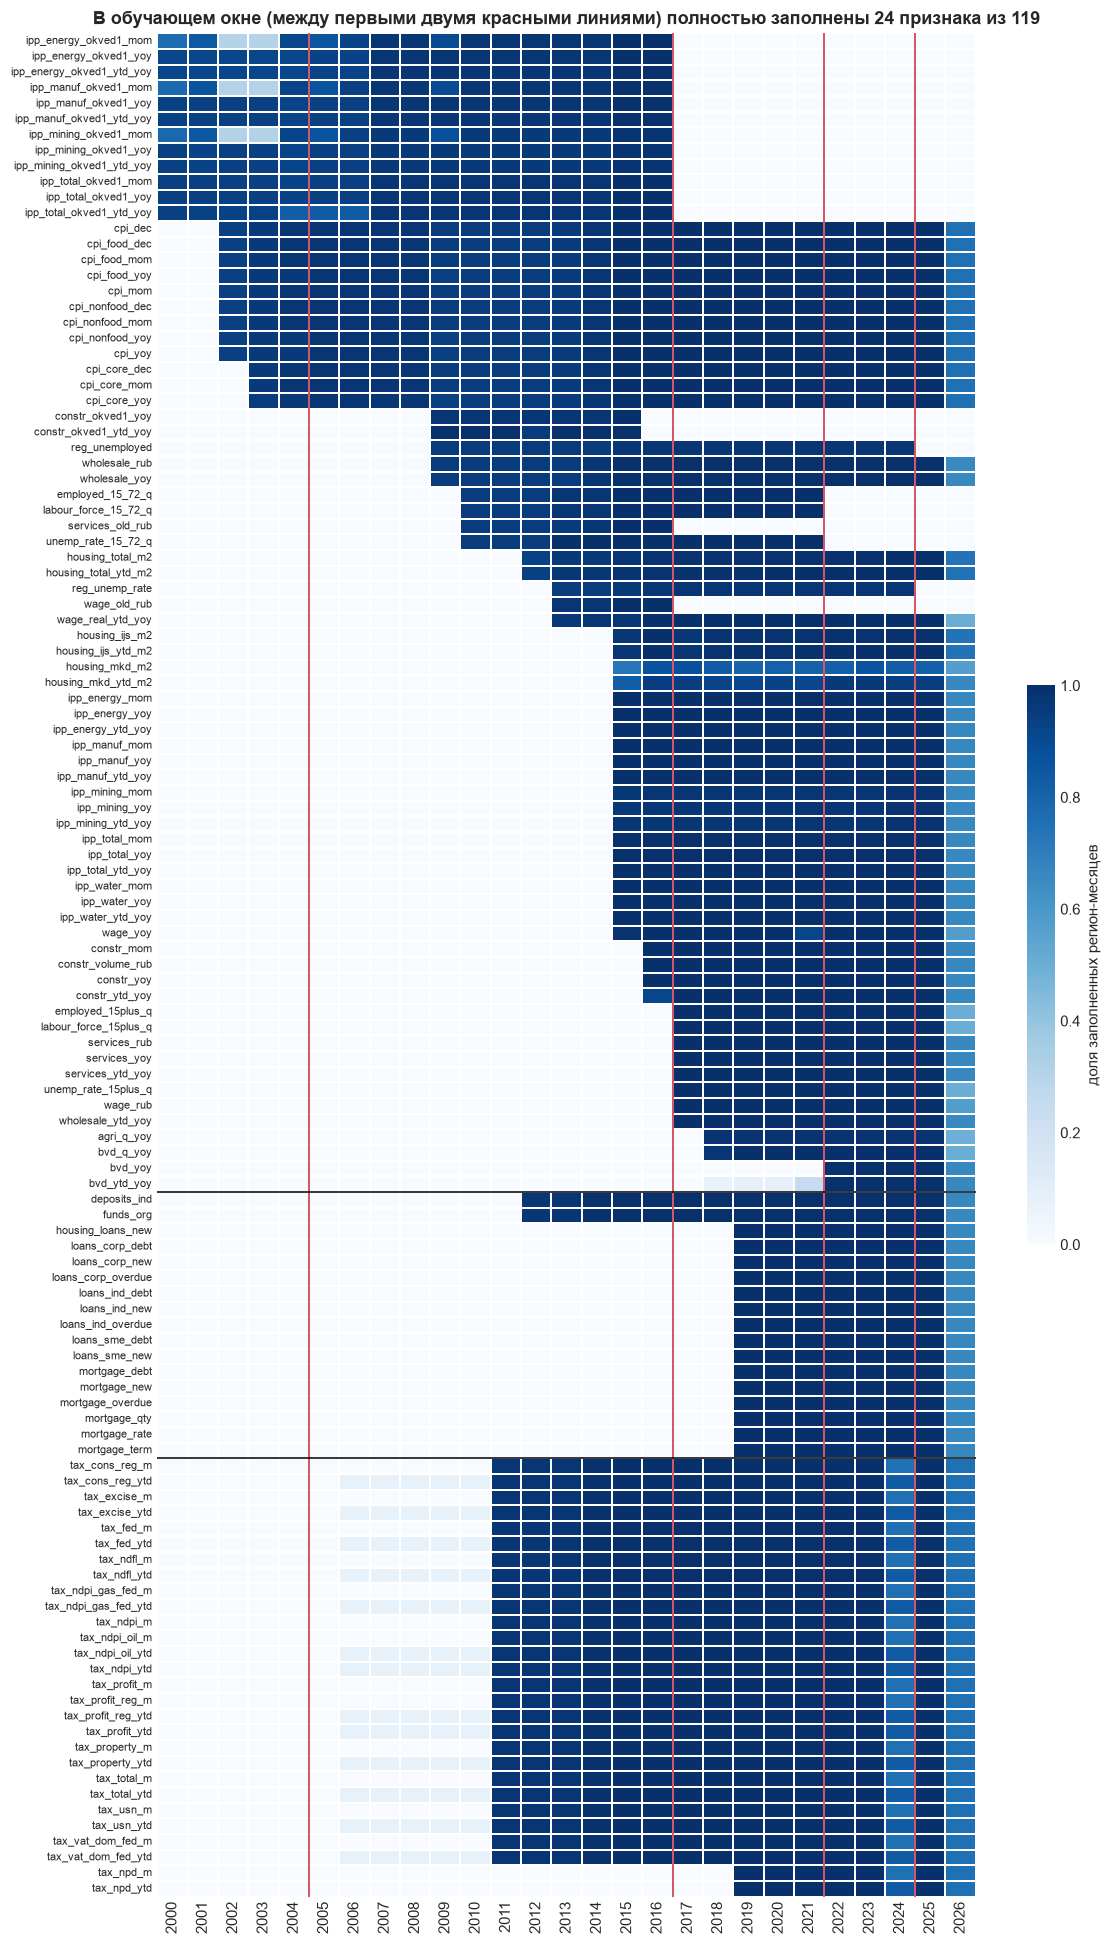

In [14]:
ML = D["features_regional_monthly_long"]
ML = ML[ML.region_id.isin(SAMPLE)].copy()
ML["year"] = ML.year.astype(int)
feats = cat[cat.table == "regional_monthly"][["feature", "group", "freq_source"]].set_index("feature")
expected = {"M": 12, "Q": 4}
cnt = ML.groupby(["feature", "year"]).value.count().unstack(fill_value=0)
den = feats.freq_source.map(expected).reindex(cnt.index) * len(SAMPLE)
fill = cnt.div(den, axis=0).clip(upper=1).reindex(columns=range(2000, 2027), fill_value=0)

grp_order = feats.reindex(fill.index).sort_values(["group"]).index
first_year = (fill > 0.5).idxmax(axis=1)
grp_order = sorted(fill.index, key=lambda f: (feats.loc[f, "group"], first_year[f], f))
fill = fill.loc[grp_order]

fig, ax = plt.subplots(figsize=(12, 22))
sns.heatmap(fill, cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "доля заполненных регион-месяцев", "shrink": 0.3},
            linewidths=0.1, linecolor="white")
for x in [TRAIN[0] - 2000, TRAIN[1] + 1 - 2000, VAL[1] + 1 - 2000, TEST[1] + 1 - 2000]:
    ax.axvline(x, color=C_ACC, lw=1.2)
g_sorted = [feats.loc[f, "group"] for f in fill.index]
for i in range(1, len(g_sorted)):
    if g_sorted[i] != g_sorted[i - 1]:
        ax.axhline(i, color="black", lw=1)
ax.tick_params(axis="y", labelsize=7)
ax.set_ylabel("")
ax.set_xlabel("")
ax.set_title("В обучающем окне (между первыми двумя красными линиями) полностью заполнены 24 признака из 119")
plt.show()

In [15]:
def avail_share(a, b):
    sub = fill.loc[:, a:b]
    return sub.mean(axis=1)

av = pd.DataFrame({lab: avail_share(a, b) for lab, (a, b) in
                   [("обучение", TRAIN), ("валидация", VAL), ("тест", TEST)]})
av["group"] = feats.group.reindex(av.index)
summary = pd.DataFrame({lab: [(av[lab] >= 0.9).sum(), ((av[lab] > 0.1) & (av[lab] < 0.9)).sum(), (av[lab] <= 0.1).sum()]
                        for lab in ["обучение", "валидация", "тест"]},
                       index=[">=90% ячеек", "частично", "<=10% ячеек"])
print("Региональных месячных признаков всего:", len(av))
summary

Региональных месячных признаков всего: 119


,обучение,валидация,тест
>=90% ячеек,24,81,99
частично,62,20,1
<=10% ячеек,33,18,19


In [16]:
#Распределение признаков с >=90% ячеек по группе признаков
av.groupby("group")[["обучение", "валидация", "тест"]].apply(lambda d: (d >= 0.9).sum()).assign(
    всего=av.groupby("group").size())

,обучение,валидация,тест,всего
group,,,,
1. Официальная месячная статистика,24,53,54,74
3. Финансы и кредит,0,2,17,17
4. Бюджет и налоги,0,26,28,28


Это главная проблема датасета для текущего дизайна. В обучающем окне 2005–2016 годов на 90% и больше заполнены только 24 из 119 региональных месячных признаков: ИПП и ИПЦ. Кредитов нет совсем (0 из 17, ряды ЦБ начинаются в 2019 году), налоги помесячно есть только с 2011 года (0 из 28 заполнены на 90% за всё окно). Торговля и строительство начинаются с 2009 года, ввод жилья с 2012-го. На валидации полных признаков уже 81, на тесте 99.

Выходит, что модель, обученная на 2005–2016 годах, видит только промышленность и цены, а на тесте ей доступно в 4 раза больше рядов. Вариантов три: 
- сдвинуть начало обучения к 2011–2012 годам (меньше лет, но полный набор налогов, строительства и торговли); 
- брать модели, которые сами работают с пропусками;
- делать две версии, длинную на ИПП и ИПЦ и короткую на всех рядах. 

!!! Это надо обсудить.

### 3.1. Пробелы по регионам

Матрица «регион x признак» из `coverage_matrix_regional_monthly.csv` с числом доступных месяцев. Нормирую на максимум по признаку и показываю регионы, у которых средняя заполненность ниже остальных.

In [17]:
cm = pd.read_csv(P / "coverage_matrix_regional_monthly.csv").set_index("region_id")
cm = cm.loc[cm.index.isin(SAMPLE)]
cm_n = cm / cm.max()
reg_fill = cm_n.mean(axis=1).sort_values()
low = reg_fill.head(12)
gaps = (cm_n < 0.8).sum(axis=1).reindex(low.index)
pd.DataFrame({"регион": [NAME[r] for r in low.index], "средняя заполненность": low.values,
              "признаков с <80% месяцев": gaps.values}).set_index("регион")

,средняя заполненность,признаков с <80% месяцев
регион,,
г. Севастополь,0.74,67
Республика Крым,0.76,64
Архангельская область без НАО,0.90,32
Тюменская область без ХМАО и ЯНАО,0.90,32
Чеченская Республика,0.94,13
Чукотский автономный округ,0.96,9
г. Москва,0.96,6
Республика Ингушетия,0.98,4
Магаданская область,0.99,2


In [18]:
# Месяцы, которых нет сразу у всех регионов внутри периода, где признак публикуется
holes = []
for f, d in ML.groupby("feature"):
    per = feats.loc[f, "freq_source"]
    months = range(1, 13) if per == "M" else (3, 6, 9, 12)
    yrs = d.groupby("year").value.count()
    y0, y1 = yrs[yrs > 0].index.min(), yrs[yrs > 0].index.max()
    have = set(zip(d.dropna(subset=["value"]).year, d.dropna(subset=["value"]).month))
    last = max(have)
    miss = [(y, m) for y in range(y0, y1 + 1) for m in months if (y, m) not in have and (y, m) < last and (y, m) > min(have)]
    if miss:
        holes.append({"признак": f, "пропущено месяцев": len(miss)})
holes = pd.DataFrame(holes).set_index("признак").sort_values("пропущено месяцев", ascending=False)
print("признаков со сплошными дырами:", len(holes))
holes.head(25)

признаков со сплошными дырами: 33


,пропущено месяцев
признак,
tax_ndpi_oil_ytd,46
tax_ndpi_gas_fed_ytd,46
tax_vat_dom_fed_ytd,46
tax_usn_ytd,46
tax_total_ytd,46
tax_cons_reg_ytd,46
tax_property_ytd,46
tax_excise_ytd,46
tax_profit_ytd,46


По регионам меньше всего данных у Севастополя и Крыма (средняя заполненность 74–76%, их ряды начинаются в 2014–2015 годах) и у двух областей (Тюменская и Архангельская области, 90%, у них 32 признака заполнены меньше чем на 80%). Остальные регионы заполнены на 94% и выше.

Сплошные дыры, месяцы, которых нет ни у одного региона, нашлись в 33 признаках.

## 4. Качество признаков

### 4.1. Нули и выбросы в индексах

Индексы (`*_yoy`, `*_mom`, `*_ytd_yoy`, `*_dec`) в процентах к прошлому году, при этом прошлый год = 100. Считаю на обучающем окне по регионам количество нулей, долю значений вне диапазона [50, 200] и экстремумы.

In [19]:
idx_feats = [f for f in feats.index if any(f.endswith(s) for s in ["_yoy", "_mom", "_dec"])]
mi = ML[ML.feature.isin(idx_feats)]
mi_tr = mi[mi.year.between(*TRAIN)]
qual = mi_tr.groupby("feature").value.agg(
    n="count", нулей=lambda s: (s == 0).sum(),
    out_50_200=lambda s: ((s != 0) & ((s < 50) | (s > 200))).mean() * 100,
    p01=lambda s: s[s > 0].quantile(.01), p99=lambda s: s[s > 0].quantile(.99), max="max")
qual = qual[qual.n > 0].sort_values("out_50_200", ascending=False)
qual.head(15)

,n,нулей,out_50_200,p01,p99,max
feature,,,,,,
constr_mom,1020,0,12.25,12.94,289.36,656.00
constr_yoy,1020,0,7.84,28.89,273.67,522.60
constr_okved1_yoy,6996,78,7.73,28.62,297.96,"2,583.60"
ipp_mining_okved1_yoy,11793,28,6.25,35.10,359.76,"7,961.80"
ipp_mining_okved1_mom,11631,17,5.15,34.00,278.03,"9,400.90"
constr_okved1_ytd_yoy,7084,212,4.07,42.04,248.46,"1,020.50"
ipp_mining_yoy,1980,0,3.79,45.22,289.36,"1,449.70"
ipp_mining_mom,1985,0,3.78,39.48,230.01,462.90
ipp_mining_okved1_ytd_yoy,11793,11,3.77,42.98,281.87,"5,584.50"


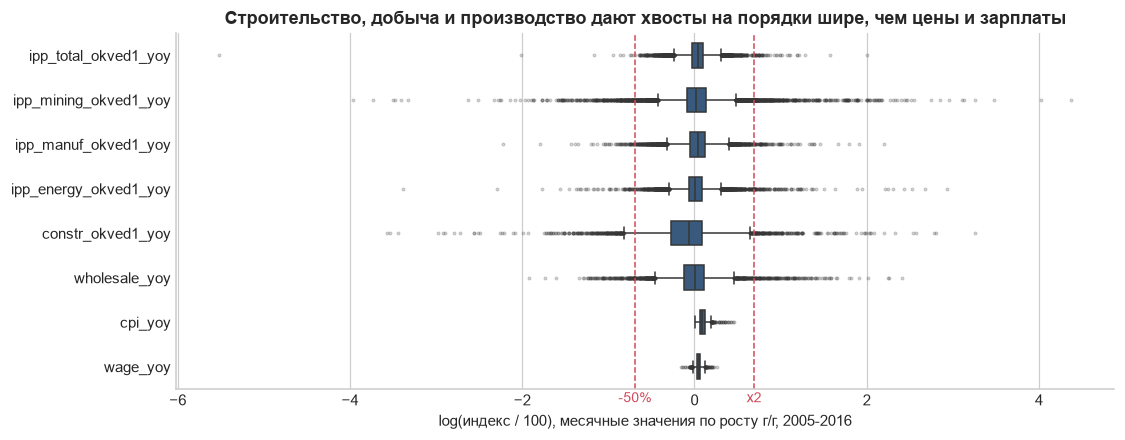

In [20]:
main_idx = ["ipp_total_okved1_yoy", "ipp_mining_okved1_yoy", "ipp_manuf_okved1_yoy", "ipp_energy_okved1_yoy",
            "constr_okved1_yoy", "wholesale_yoy", "cpi_yoy", "wage_yoy"]
d = mi_tr[mi_tr.feature.isin(main_idx) & (mi_tr.value > 0)].copy()
d["log_ratio"] = np.log(d.value / 100)
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=d, y="feature", x="log_ratio", order=main_idx, ax=ax, color=C_MAIN, fliersize=1.5, width=0.55,
            flierprops={"alpha": 0.3})
for x, lab in [(np.log(0.5), "-50%"), (np.log(2), "x2")]:
    ax.axvline(x, color=C_ACC, ls="--", lw=1)
    ax.text(x, 7.8, lab, color=C_ACC, ha="center", fontsize=9)
ax.set_xlabel("log(индекс / 100), месячные значения по росту г/г, 2005-2016")
ax.set_ylabel("")
ax.set_title("Строительство, добыча и производство дают хвосты на порядки шире, чем цены и зарплаты")
plt.show()

В строительстве и добыче от 3 до 12% месячных значений лежат вне диапазона [50, 200], то есть показывают падение или рост больше чем вдвое к прошлому году. Цены и зарплаты лежат в узком коридоре. Нулей в строительстве с начала года 212, при этом они означают не нулевой выпуск, а пропуски.

Вывод: нули в индексах заменить на пропуски, индексы перевести в логарифмическую шкалу log(индекс/100).

### 4.2. Стык ОКВЭД-2007 и ОКВЭД2 в ИПП

ИПП публикуется в обеих классификациях за 2015–2016 годы. Можно проверить, допустимо ли склеивать ряды без поправок.

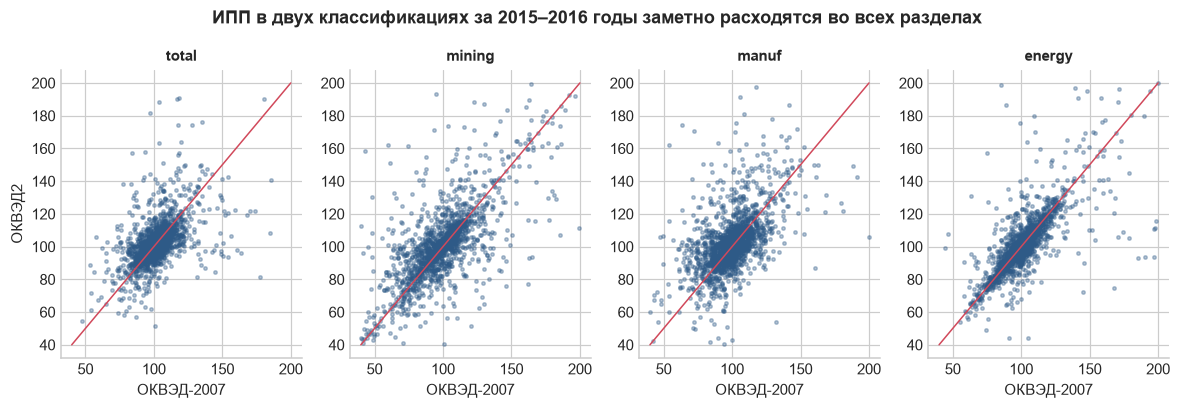

,n,corr,"средняя разница, п.п.",медиана |разницы|,"доля |разницы| > 5 п.п., %"
ряд,,,,,
ipp_total,2040,0.56,1.41,4.50,46.13
ipp_mining,1964,0.67,2.49,4.70,47.66
ipp_manuf,2040,0.60,2.52,6.50,57.84
ipp_energy,2027,0.54,-0.08,3.00,33.70


In [21]:
pairs = [("ipp_total_yoy", "ipp_total_okved1_yoy"), ("ipp_mining_yoy", "ipp_mining_okved1_yoy"),
         ("ipp_manuf_yoy", "ipp_manuf_okved1_yoy"), ("ipp_energy_yoy", "ipp_energy_okved1_yoy")]
wide = ML[ML.year.between(2015, 2016)].pivot_table(index=["region_id", "year", "month"], columns="feature", values="value")
res = []
for new, old in pairs:
    x = wide[[new, old]].replace(0, np.nan).dropna()
    x = x[(x[new].between(20, 500)) & (x[old].between(20, 500))]
    diff = x[new] - x[old]
    res.append({"ряд": new.replace("_yoy", ""), "n": len(x), "corr": x[new].corr(x[old]),
                "средняя разница, п.п.": diff.mean(), "медиана |разницы|": diff.abs().median(),
                "доля |разницы| > 5 п.п., %": (diff.abs() > 5).mean() * 100})
splice = pd.DataFrame(res).set_index("ряд")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=False)
for ax, (new, old) in zip(axes, pairs):
    x = wide[[new, old]].replace(0, np.nan).dropna()
    x = x[(x[new].between(40, 200)) & (x[old].between(40, 200))]
    ax.scatter(x[old], x[new], s=5, alpha=0.35, color=C_MAIN)
    lo, hi = 40, 200
    ax.plot([lo, hi], [lo, hi], color=C_ACC, lw=1)
    ax.set_title(new.replace("ipp_", "").replace("_yoy", ""), fontsize=10)
    ax.set_xlabel("ОКВЭД-2007")
axes[0].set_ylabel("ОКВЭД2")
fig.suptitle("ИПП в двух классификациях за 2015–2016 годы заметно расходятся во всех разделах", fontweight="bold", y=1.04)
plt.show()
splice

In [22]:
# Тот же стык на уровне РФ и на годовых значениях
rf_ipp = (D["features_regional_monthly_long"].query("region_id == 'rossiyskaya_federatsiya' and year in [2015, 2016] and month == 12")
          .pivot_table(index="year", columns="feature", values="value")[["ipp_total_okved1_ytd_yoy", "ipp_total_ytd_yoy"]])
print("ИПП РФ за год, %:")
print(rf_ipp.rename(columns={"ipp_total_okved1_ytd_yoy": "ОКВЭД-2007", "ipp_total_ytd_yoy": "ОКВЭД2"}).to_string())
ann = dec_tmp = ML[(ML.month == 12) & ML.year.isin([2015, 2016]) & ML.feature.isin(["ipp_total_ytd_yoy", "ipp_total_okved1_ytd_yoy"])]
ann = ann.pivot_table(index=["region_id", "year"], columns="feature", values="value").dropna()
dif = ann.ipp_total_ytd_yoy - ann.ipp_total_okved1_ytd_yoy
print(f"\nРегионы, годовой ИПП: corr = {ann.corr().iloc[0, 1]:.2f}, медиана |разницы| = {dif.abs().median():.1f} п.п., "
      f"|разница| > 5 п.п. у {(dif.abs() > 5).mean() * 100:.0f}% пар регион-год")

ИПП РФ за год, %:
feature  ОКВЭД-2007  ОКВЭД2
year                       
2015          96.60  100.20
2016         101.10  101.80

Регионы, годовой ИПП: corr = 0.57, медиана |разницы| = 1.6 п.п., |разница| > 5 п.п. у 17% пар регион-год


Ряды в двух классификациях не взаимозаменяемы. Помесячно корреляция 0,54–0,67, а у больше, чем трети пар «регион-месяц» разница больше 5 п.п. На годовых значениях расхождение меньше (корреляция 0,57, медиана разницы 1,6 п.п., больше 5 п.п. у 17% пар), но и по РФ в целом 2015 год выглядит по-разному: 96,6% в ОКВЭД-2007 и 100,2% в ОКВЭД2.

В разделе 5 я беру ОКВЭД-2007 до 2016 года и ОКВЭД2 с 2017-го для признаков и цели одновременно. 

Вывод: стоит добавить индикатор режима классификации.

### 4.3. Сезонность признаков

Помесячные признаки возможно имеют сильную сезонность. На графике - медианная доля каждого месяца в годовой сумме по регионам за 2017–2021 годы.

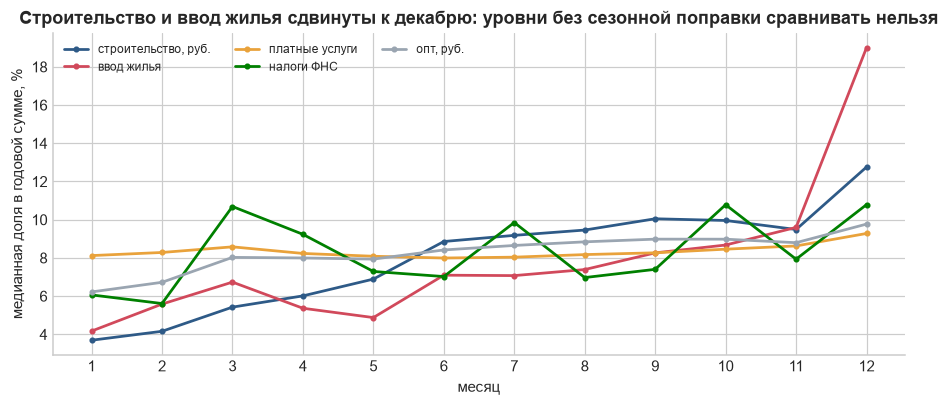

month,1,2,3,4,5,6,7,8,9,10,11,12
feature,,,,,,,,,,,,
"строительство, руб.",3.70,4.20,5.40,6.00,6.90,8.90,9.20,9.50,10.00,10.00,9.50,12.80
ввод жилья,4.20,5.60,6.70,5.40,4.90,7.10,7.10,7.40,8.30,8.70,9.60,19.00
платные услуги,8.10,8.30,8.60,8.20,8.10,8.00,8.00,8.20,8.30,8.50,8.60,9.30
налоги ФНС,6.10,5.60,10.70,9.20,7.30,7.00,9.90,7.00,7.40,10.80,7.90,10.80
"опт, руб.",6.20,6.70,8.00,8.00,7.90,8.40,8.70,8.80,9.00,9.00,8.80,9.80


In [23]:
flows = {"tax_total_m": "налоги ФНС", "housing_total_m2": "ввод жилья", "constr_volume_rub": "строительство, руб.",
         "wholesale_rub": "опт, руб.", "services_rub": "платные услуги"}
fl = ML[ML.feature.isin(flows) & ML.year.between(2017, 2021)].copy()
fl["share"] = fl.value / fl.groupby(["feature", "region_id", "year"]).value.transform("sum") * 100
prof = fl.groupby(["feature", "month"]).share.median().unstack(0).rename(columns=flows)
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, c in enumerate(prof.columns):
    ax.plot(prof.index, prof[c], marker="o", ms=3, lw=1.8,
            color=[C_MAIN, C_ACC, C_SEC, "green", C_GREY][i], label=c)
ax.set_xticks(range(1, 13))
ax.set_xlabel("месяц")
ax.set_ylabel("медианная доля в годовой сумме, %")
ax.set_title("Строительство и ввод жилья сдвинуты к декабрю: уровни без сезонной поправки сравнивать нельзя")
ax.legend(fontsize=8, ncol=3)
plt.show()
prof.round(1).T

На декабрь приходится 12,8% годового объёма строительства (в январе 3,7%) и 19% годового ввода жилья. Налоги идут волнами по срокам уплаты: пики в марте, июле, октябре и декабре (около 10–11% против 6–8% в соседних месяцах). Платные услуги и опт почти равномерны.

Индексы к прошлому месяцу без сезонной поправки для модели не годятся.
Для годовой цели они не добавляют информации, так как двенадцать перемноженных месячных индексов дают тот же годовой рост, что уже есть в индексе с начала года.

Поэтому беру индексы к прошлому году и с начала года. Индексы к прошлому месяцу можно взять только после сезонной поправки, а на коротких региональных рядах её не сделать надёжно.

## 5. Связь годовых агрегатов признаков с ростом ВРП

Цель годовая, а признаки месячные, поэтому свожу каждый месячный ряд к году так, как он будет доступен к концу года t:

- индексы «с начала года» беру за декабрь, это и есть годовой рост;
- где ряда с начала года нет (например, опт до 2017 года), беру среднее месячных г/г;
- значения рядов с единицей измерения в рублях суммирую за год и дефлирую региональным ИПЦ декабрь к декабрю;
- ряды ОКВЭД-2007 использую до 2016 года, ОКВЭД2 с 2017 года (для строительства граница 2015/2016, как в источнике);

Признаки с первым годом после 2016 в обучении не участвуют, их связь видна только на валидации.

In [24]:
MW = ML.pivot_table(index=["region_id", "year", "month"], columns="feature", values="value").reset_index()

FEAT_COLS = [c for c in MW.columns if c not in ("region_id", "year", "month")]
MWc = MW.copy()
MWc[FEAT_COLS] = MWc[FEAT_COLS].replace(0, np.nan)
dec = MWc[MWc.month == 12].set_index(["region_id", "year"])
AN = D["features_regional_annual_wide"].copy()
AN["year"] = AN.year.astype(int)
AN = AN[AN.region_id.isin(SAMPLE)].set_index(["region_id", "year"])


def splice_dec(new, old, last_old=2016):
    s_old = dec[old].where(dec.index.get_level_values("year") <= last_old) if old else None
    s_new = dec[new].where(dec.index.get_level_values("year") > last_old)
    return s_new.fillna(s_old) if old else s_new


def annual_mean(f):
    return MWc.groupby(["region_id", "year"])[f].mean()


F = pd.DataFrame(index=dec.index)
F["ИПП"] = splice_dec("ipp_total_ytd_yoy", "ipp_total_okved1_ytd_yoy")
F["ИПП добыча"] = splice_dec("ipp_mining_ytd_yoy", "ipp_mining_okved1_ytd_yoy")
F["ИПП обработка"] = splice_dec("ipp_manuf_ytd_yoy", "ipp_manuf_okved1_ytd_yoy")
F["ИПП энергетика"] = splice_dec("ipp_energy_ytd_yoy", "ipp_energy_okved1_ytd_yoy")
F["строительство"] = splice_dec("constr_ytd_yoy", "constr_okved1_ytd_yoy", last_old=2015)
F["опт"] = dec["wholesale_ytd_yoy"].fillna(annual_mean("wholesale_yoy").reindex(dec.index))
F["платные услуги"] = dec["services_ytd_yoy"]
F["реальная зарплата"] = dec["wage_real_ytd_yoy"]
F["ИПЦ дек/дек"] = dec["cpi_dec"]
F["выпуск базовых видов"] = dec["bvd_ytd_yoy"]
hous = dec["housing_total_ytd_m2"]
F["ввод жилья"] = hous / hous.groupby("region_id").shift(1) * 100
tax = dec["tax_total_ytd"]
F["налоги реал."] = tax / tax.groupby("region_id").shift(1) / (dec["cpi_dec"] / 100) * 100
ndfl = dec["tax_ndfl_ytd"]
F["НДФЛ реал."] = ndfl / ndfl.groupby("region_id").shift(1) / (dec["cpi_dec"] / 100) * 100
F["сельское хоз."] = AN["agri_y_yoy"].fillna(AN["agri_old_y_yoy"]).replace(0, np.nan).reindex(F.index)
F["розница (год)"] = AN["retail_y_yoy"].replace(0, np.nan).reindex(F.index)
ld = dec["loans_corp_debt"]
F["кредит ЮЛ реал."] = ld / ld.groupby("region_id").shift(1) / (dec["cpi_dec"] / 100) * 100

n_inf = int(np.isinf(F.values).sum())
F = F.replace([np.inf, -np.inf], np.nan)
F = F.reset_index()
F["ВВП"] = F.year.map(gdp_g) + 100
F = F.merge(TS[["region_id", "year", "g"]], on=["region_id", "year"], how="left")
FEATS = [c for c in F.columns if c not in ("region_id", "year", "g")]
F[FEATS] = F[FEATS] - 100  # всё в приросте, п.п.

first = F.groupby(lambda i: 0)[FEATS].apply(lambda d: d.notna().groupby(F.year).mean().gt(0.8).idxmax()).T[0]
n_zero = int((MW.loc[MW.month == 12, FEAT_COLS] == 0).sum().sum())
print(f"Нулей в декабрьских значениях заменено на пропуск: {n_zero}; бесконечностей после деления заменено: {n_inf}")
print("Первый год, когда признак есть у >80% регионов:")
print(first.sort_values().to_string())

Нулей в декабрьских значениях заменено на пропуск: 4377; бесконечностей после деления заменено: 0
Первый год, когда признак есть у >80% регионов:
сельское хоз.           1999
ИПП                     2000
ИПП добыча              2000
ИПП обработка           2000
ИПП энергетика          2000
розница (год)           2000
ИПЦ дек/дек             2002
ВВП                     2002
налоги реал.            2007
НДФЛ реал.              2007
опт                     2009
строительство           2009
реальная зарплата       2013
ввод жилья              2013
платные услуги          2017
выпуск базовых видов    2018
кредит ЮЛ реал.         2020


Корреляции c ВРП считаю двумя способами. Обычная корреляция по панели смешивает общий шок года и регионы внутри года. Для nowcasting региона важна вторая часть, поэтому рядом показываю корреляцию после вычитания среднего по году из цели и из признака (внутри года).

Рядом с обычной корреляцией (Пирсон) считаю ранговую внутри года (Спирмен): ранжирую регионы по признаку и по росту ВРП внутри каждого года. Если ранговая заметно ниже, связь держится на нескольких крайних значениях.

Проводим винзоризацию, чтобы исключить влияние экстремальных значений на расчет корреляции. Пороги 1-го и 99-го перцентилей каждого признака считаются на обучающем окне и применяются к валидации, то есть значения экстремальнее этих порогов удаляются из анализа корреляции. У трёх признаков (платные услуги, выпуск базовых видов, кредиты) истории в обучении нет. Для них пороги беру по первому году валидации, где признак есть у 60 и больше регионов, а сам этот год исключаю из корреляций.

Пороги по первому году валидации (этот год исключён из корреляций): {'платные услуги': 2017, 'выпуск базовых видов': 2018, 'кредит ЮЛ реал.': 2020}


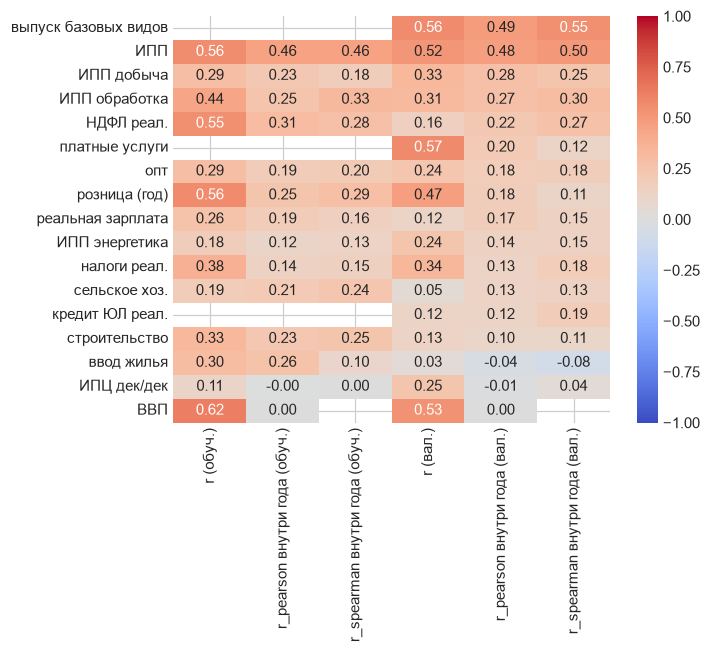

In [25]:
def winsor_bounds(s):
    return s.quantile(0.01), s.quantile(0.99)


Fw = F.copy()
bounds = {}
THR_YEAR = {}   # признаки без истории в обучении
for f in FEATS:
    base = Fw.loc[Fw.year.between(*TRAIN), f].dropna()
    if len(base) < 100:
        cnt = Fw.loc[Fw.year.between(*VAL), ["year", f]].dropna().groupby("year").size()
        THR_YEAR[f] = int(cnt[cnt >= 60].index.min())
        base = Fw.loc[Fw.year == THR_YEAR[f], f].dropna()
    bounds[f] = winsor_bounds(base)
    Fw[f] = Fw[f].clip(*bounds[f])
print("Пороги по первому году валидации (этот год исключён из корреляций):", THR_YEAR)


def within_corr(z, f, method="pearson"):
    z = z[["year", f, "g"]].copy()
    if method == "spearman":
        z[[f, "g"]] = z.groupby("year")[[f, "g"]].rank()
    w = z[[f, "g"]] - z.groupby("year")[[f, "g"]].transform("mean")
    return w[f].corr(w.g) if w[f].std() > 0 else np.nan


def corr_table(df, a, b):
    x = df[df.year.between(a, b)]
    out = {}
    for f in FEATS:
        z = x[["year", f, "g"]].dropna()
        if f in THR_YEAR:
            z = z[z.year > THR_YEAR[f]]
        if len(z) < 60 or z[f].std() == 0:
            out[f] = (np.nan, np.nan, np.nan, len(z))
            continue
        out[f] = (z[f].corr(z.g), within_corr(z, f), within_corr(z, f, "spearman"), len(z))
    return pd.DataFrame(out, index=["r", "r_pearson внутри года", "r_spearman внутри года", "n"]).T


ct = corr_table(Fw, *TRAIN).add_suffix(" (обуч.)").join(corr_table(Fw, *VAL).add_suffix(" (вал.)"))
ct = ct.sort_values("r_pearson внутри года (вал.)", key=lambda s: -s.abs())
rcols = [c for c in ct.columns if not c.startswith("n")]
sns.heatmap(ct[rcols], annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.show()

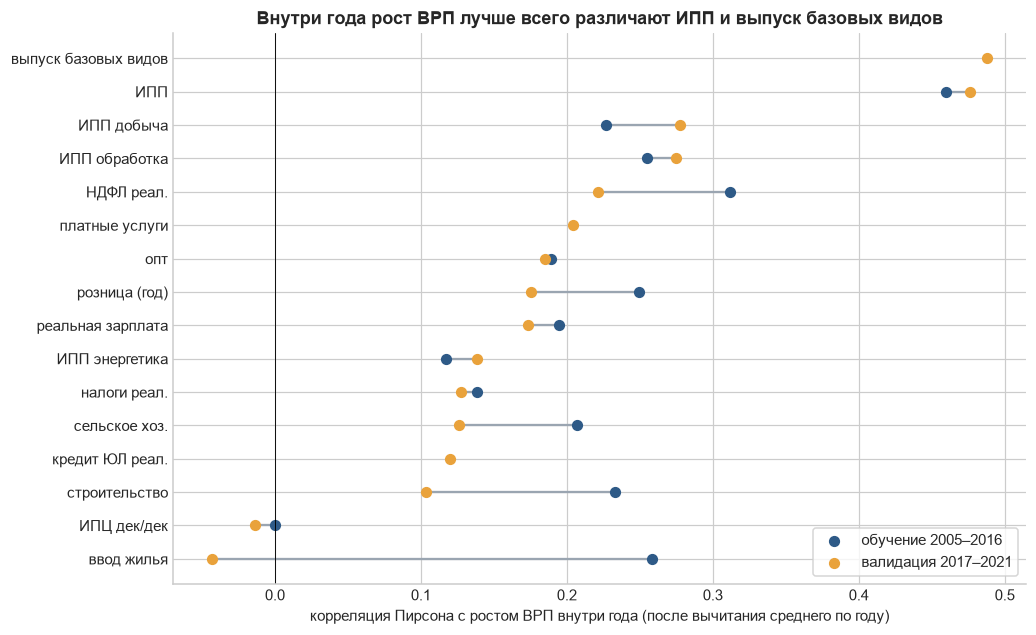

In [26]:
plot = ct.drop(index=["ВВП"]).copy()
plot = plot.sort_values("r_pearson внутри года (вал.)")
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(plot))
for i, (_, row) in enumerate(plot.iterrows()):
    vals = [row["r_pearson внутри года (обуч.)"], row["r_pearson внутри года (вал.)"]]
    if not np.isnan(vals[0]):
        ax.plot(vals, [i, i], color=C_GREY, lw=1.5, zorder=1)
ax.scatter(plot["r_pearson внутри года (обуч.)"], y, color=PERIOD_COL["обучение"], s=40, zorder=2, label="обучение 2005–2016")
ax.scatter(plot["r_pearson внутри года (вал.)"], y, color=PERIOD_COL["валидация"], s=40, zorder=2, label="валидация 2017–2021")
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(plot.index)
ax.set_xlabel("корреляция Пирсона с ростом ВРП внутри года (после вычитания среднего по году)")
ax.set_title("Внутри года рост ВРП лучше всего различают ИПП и выпуск базовых видов")
ax.legend(loc="lower right", frameon=True)
plt.show()

ИПП самый сильный признак внутри года и при этом стабильный: корреляция 0,46 на обучении и 0,48 на валидации, по рангам 0,46 и 0,5. Рядом с ним выпуск по базовым видам: 0,49 на валидации, по рангам 0,55. Этот ряд есть только с 2018 года, 2018 год ушёл на пороги винзоризации, так что проверка идёт на 2019–2021 годах. Дальше идут добыча и обработка (0,23–0,28), реальный НДФЛ (0,31 на обучении и 0,22 на валидации, по рангам 0,28 и 0,27) и сельское хозяйство (0,21 и 0,13).

Без вычитания года картина обманчива. Розница даёт 0,56 по панели и только 0,25 внутри года, у ВВП корреляция с целью 0,62, а внутри года по построению ноль. Большая часть дисперсии признаков в панели приходится на общий годовой шок, который ВВП и так показывает.

Ранговая корреляция показывает, где связь держится на нескольких крайних значениях. У платных услуг на валидации 0,20 по Пирсону и 0,12 по рангам, у розницы 0,18 и 0,11, у ввода жилья на обучении 0,26 и 0,10. Ввод жилья к тому же на валидации уходит ниже нуля (−0,04), строительство с 0,23 до 0,1. ИПЦ с ростом ВРП внутри года не связан.

Даже лучший признак объясняет около четверти дисперсии внутри года ($0,48^2 = 0,23$).

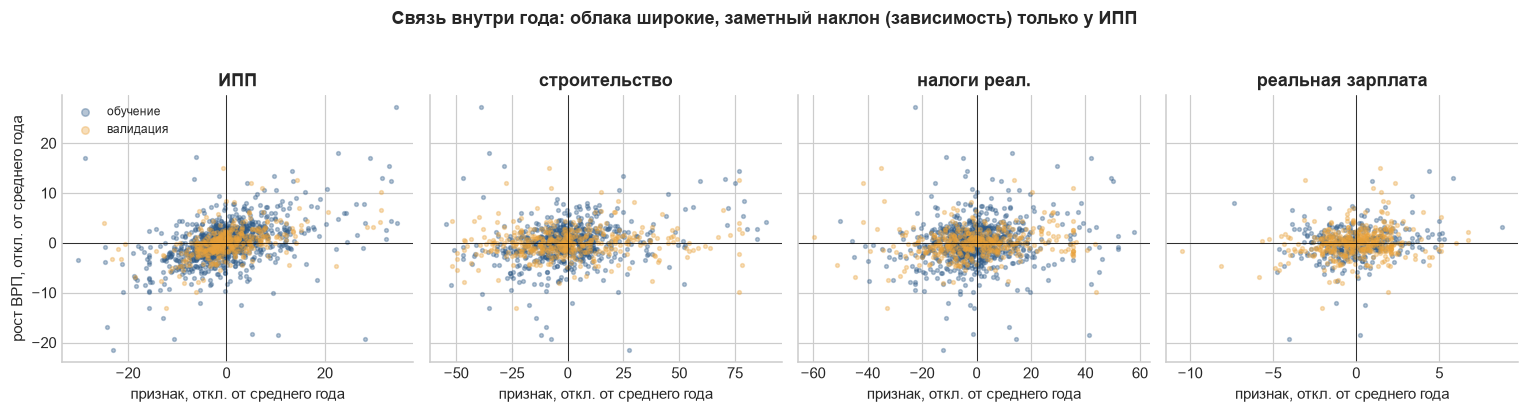

In [27]:
top = ["ИПП", "строительство", "налоги реал.", "реальная зарплата"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, f in zip(axes, top):
    for lab, (a, b) in [("обучение", TRAIN), ("валидация", VAL)]:
        z = Fw[Fw.year.between(a, b)][[f, "g", "year"]].dropna()
        z = z - z.groupby("year").transform("mean")
        ax.scatter(z[f], z.g, s=6, alpha=0.35, color=PERIOD_COL[lab], label=lab)
    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_title(f)
    ax.set_xlabel("признак, откл. от среднего года")
axes[0].set_ylabel("рост ВРП, откл. от среднего года")
axes[0].legend(fontsize=8, markerscale=2)
fig.suptitle("Связь внутри года: облака широкие, заметный наклон (зависимость) только у ИПП", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Пространственная зависимость

Вопрос к EDA 5 предполагает, что связи между регионами несут сигнал. Для проверки я выбрал глобальный индекс Морана для роста ВРП по годам с матрицей соседства queen (регионы с общей границой), строки нормировал. Крым и Севастополь в матрице отсутствуют, Калининградская и Сахалинская области не имеют соседей по суше.

Индекс Морана — это статистический показатель, который измеряет пространственную автокорреляцию данных, то есть показывает, насколько похожи или различны объекты в зависимости от их расположения на карте.

Значение индекса обычно лежит в диапазоне от -1 до +1:
- Ближе к +1 — указывает на кластеризацию (похожие значения располагаются рядом: например, богатые районы граничат с богатыми, а бедные — с бедными).
- Около 0 — указывает на случайное распределение (никакой пространственной связи между объектами нет).
- Ближе к -1 — указывает на регулярное или шахматное распределение.

регионов в матрице: 81 | среднее число соседей: 4.7


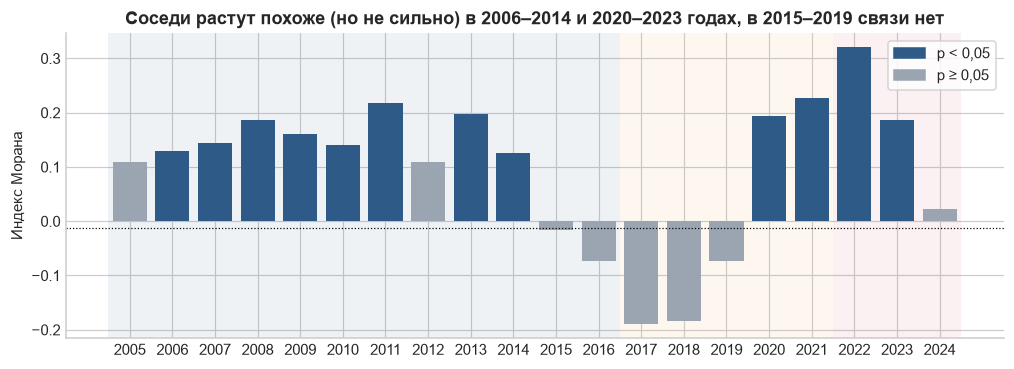

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
I,0.11,0.13,0.14,0.19,0.16,0.14,0.22,0.11,0.20,0.12,-0.02,-0.07,-0.19,-0.18,-0.07,0.19,0.23,0.32,0.19,0.02
p,0.06,0.03,0.04,0.01,0.01,0.03,0.01,0.07,0.01,0.04,0.50,0.78,1.00,0.99,0.79,0.01,0.00,0.00,0.01,0.29
n,78.00,79.00,79.00,79.00,79.00,79.00,79.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00


In [28]:
W_ids = sorted(SAMPLE & set(geo.region_id))
A = adj[adj.region_id.isin(W_ids) & adj.neighbor_id.isin(W_ids) & (adj.contiguous_queen == 1)]
idx = {r: i for i, r in enumerate(W_ids)}
W = np.zeros((len(W_ids), len(W_ids)))
for r, n in zip(A.region_id, A.neighbor_id):
    W[idx[r], idx[n]] = 1
W = np.maximum(W, W.T)
keep = W.sum(1) > 0
W, W_ids = W[keep][:, keep], [r for r, k in zip(W_ids, keep) if k]
W = W / W.sum(1, keepdims=True)
print("регионов в матрице:", len(W_ids), "| среднее число соседей:", round((W > 0).sum(1).mean(), 1))


def moran(x, W, perms=999):
    z = x - x.mean()
    I = len(x) / W.sum() * (z @ W @ z) / (z @ z)
    sims = np.array([(lambda zp: len(x) / W.sum() * (zp @ W @ zp) / (zp @ zp))(rng.permutation(z)) for _ in range(perms)])
    p = (np.sum(sims >= I) + 1) / (perms + 1)
    return I, p


mor = []
for yr in range(2005, 2025):
    s = TS[TS.year == yr].set_index("region_id").g.reindex(W_ids)
    ok = s.notna().values
    if ok.sum() < 60:
        continue
    Wy = W[ok][:, ok]
    Wy = Wy / np.where(Wy.sum(1, keepdims=True) == 0, 1, Wy.sum(1, keepdims=True))
    I, p = moran(s.values[ok], Wy)
    mor.append({"year": yr, "I": I, "p": p, "n": ok.sum()})
mor = pd.DataFrame(mor).set_index("year")

fig, ax = plt.subplots(figsize=(11, 3.6))
shade_periods(ax)
colors = [C_MAIN if p < 0.05 else C_GREY for p in mor.p]
ax.bar(mor.index.astype(int), mor.I, color=colors)
ax.set_xticks(mor.index.astype(int))
ax.set_xticklabels(mor.index.astype(int))
ax.axhline(-1 / (len(W_ids) - 1), color="black", lw=0.8, ls=":")
ax.set_ylabel("Индекс Морана")
ax.set_title("Соседи растут похоже (но не сильно) в 2006–2014 и 2020–2023 годах, в 2015–2019 связи нет")
ax.legend(handles=[mpl.patches.Patch(color=C_MAIN, label="p < 0,05"), mpl.patches.Patch(color=C_GREY, label="p ≥ 0,05")], frameon=True)
plt.show()
mor.T.round(3)

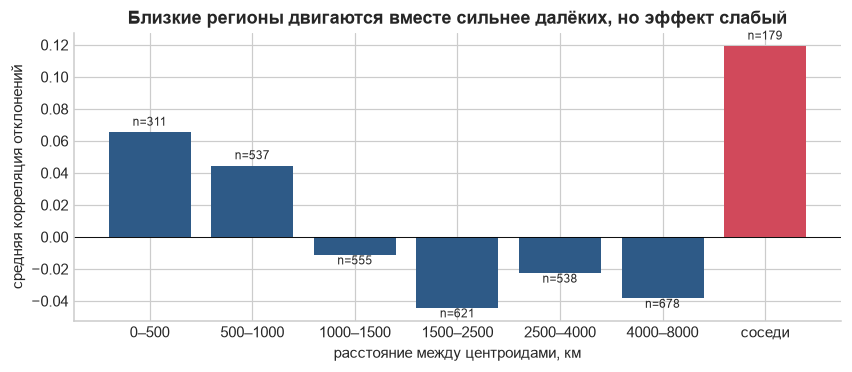

,mean,median,count
dist_bin,,,
"(0, 500]",0.07,0.07,311
"(500, 1000]",0.04,0.03,537
"(1000, 1500]",-0.01,-0.00,555
"(1500, 2500]",-0.04,-0.04,621
"(2500, 4000]",-0.02,-0.02,538
"(4000, 8000]",-0.04,-0.05,678
соседи,0.12,0.14,179


In [29]:
# Корреляция отклонений от медианы года между парами регионов в зависимости от расстояния (2005–2021)
dv = TS[TS.year.between(TRAIN[0], VAL[1])].copy()
dv["dev"] = dv.g - dv.groupby("year").g.transform("median")
M = dv.pivot(index="year", columns="region_id", values="dev")
M = M.loc[:, M.notna().sum() >= 15]
C = M.corr(min_periods=12)
pairs_d = adj[adj.region_id.isin(C.columns) & adj.neighbor_id.isin(C.columns) & (adj.region_id < adj.neighbor_id)].copy()
pairs_d["corr"] = [C.loc[a, b] for a, b in zip(pairs_d.region_id, pairs_d.neighbor_id)]
bins = [0, 500, 1000, 1500, 2500, 4000, 8000]
pairs_d["dist_bin"] = pd.cut(pairs_d.centroid_distance_km, bins)
dd = pairs_d.groupby("dist_bin", observed=True)["corr"].agg(["mean", "median", "count"])
dd.loc["соседи"] = pairs_d[pairs_d.contiguous_queen == 1]["corr"].agg(["mean", "median", "count"]).values

fig, ax = plt.subplots(figsize=(9, 3.4))
labels = [f"{int(i.left)}–{int(i.right)}" for i in dd.index[:-1]] + ["соседи"]
ax.bar(range(len(dd)), dd["mean"], color=[C_MAIN] * (len(dd) - 1) + [C_ACC])
for i, (m, n) in enumerate(zip(dd["mean"], dd["count"])):
    ax.text(i, m + 0.004 if m >= 0 else m - 0.006, f"n={int(n)}", ha="center", fontsize=8)
ax.set_xticks(range(len(dd)))
ax.set_xticklabels(labels)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("расстояние между центроидами, км")
ax.set_ylabel("средняя корреляция отклонений")
ax.set_title("Близкие регионы двигаются вместе сильнее далёких, но эффект слабый")
plt.show()
dd

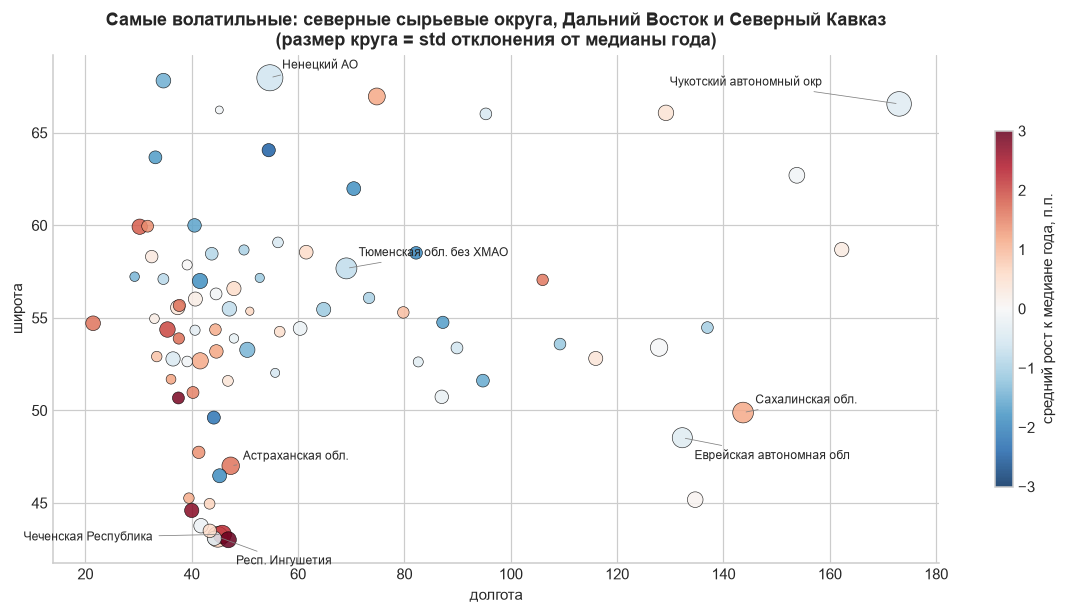

In [30]:
# Пузырьковая карта по центроидам средний - рост относительно медианы года и его волатильность (2005–2021)
mp = vol.copy()
mp["region_id"] = [k for n in mp.index for k, v in NAME.items() if v == n]
mp = mp.merge(geo[["region_id", "lon", "lat"]], on="region_id", how="left")
mp["lon"] = np.where(mp.lon < 0, mp.lon + 360, mp.lon)
fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(mp.lon, mp.lat, s=mp["std"] * 25, c=mp["mean"], cmap="RdBu_r", vmin=-3, vmax=3,
                edgecolor="black", linewidth=0.4, alpha=0.85)
offsets = [(8, 6), (-150, 12), (8, 8), (8, 6), (12, -18), (8, -14), (-130, -4), (8, 4)]
for (_, r), off in zip(mp.sort_values("std", ascending=False).head(8).iterrows(), offsets):
    ax.annotate(NAME[r.region_id].replace(" область", " обл.").replace("Республика ", "Респ. ")[:24], (r.lon, r.lat),
                xytext=off, textcoords="offset points", fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.5})
cb = plt.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label("средний рост к медиане года, п.п.")
ax.set_xlabel("долгота")
ax.set_ylabel("широта")
ax.set_title("Самые волатильные: северные сырьевые округа, Дальний Восток и Северный Кавказ\n(размер круга = std отклонения от медианы года)")
plt.show()

Пространственная зависимость есть, но непостоянная и слабая. Индекс Морана положителен и значим (p < 0,05) в 2006–2011, 2013–2014 и 2020–2023 годах, его значения 0,12–0,32. В 2015–2019 годах связи нет, а в 2017–2018 годах индекс Морана отрицателен (−0,19 и −0,18). Корреляция отклонений у соседей по границе 0,12, у регионов ближе 500 км 0,07, дальше 1500 км около нуля и слегка ниже.

Для пятого вопроса к EDA это значит, что сигнал от соседей стоит ждать прежде всего в годы общих шоков (2009, 2020, 2022).

Волатильность сосредоточена в трёх зонах: северные сырьевые округа, Дальний Восток и Северный Кавказ.

## 7. Шоки 2020 и 2022 годов

Регионы разбиты на квантили по 33% по доле добычи в ВРП за 2019 год (последний год, опубликованный к 2021 году) и по доле обработки.

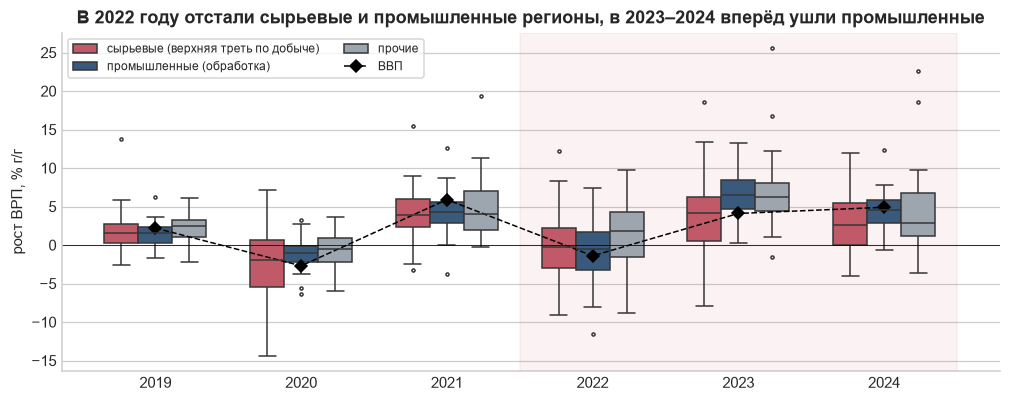

тип,промышленные (обработка),прочие,сырьевые (верхняя треть по добыче)
year,,,
2019,1.50,2.50,1.60
2020,-1.00,-0.50,-2.00
2021,4.30,4.00,3.90
2022,-0.50,1.80,-0.30
2023,6.50,6.30,4.10
2024,4.50,2.80,2.60


In [31]:
sh19 = AN.xs(2019, level="year")[["grp_share_dobycha_poleznykh_iskopaemykh", "grp_share_obrabatyvayushchie_proizvodstva"]]
sh19.columns = ["добыча", "обработка"]
sh19["тип"] = "прочие"
sh19.loc[sh19["добыча"] >= sh19["добыча"].quantile(2 / 3), "тип"] = "сырьевые (верхняя треть по добыче)"
sh19.loc[(sh19["тип"] == "прочие") & (sh19["обработка"] >= sh19["обработка"].quantile(2 / 3)), "тип"] = "промышленные (обработка)"
sk = TS[TS.year.between(2019, 2024)].merge(sh19["тип"].reset_index(), on="region_id")
sk["dev"] = sk.g - sk.year.map(gdp_g)
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=sk, x="year", y="g", hue="тип", ax=ax, palette=[C_ACC, C_MAIN, C_GREY], fliersize=2, width=0.7,
            hue_order=["сырьевые (верхняя треть по добыче)", "промышленные (обработка)", "прочие"])
ax.plot(range(6), [gdp_g[y] for y in range(2019, 2025)], color="black", marker="D", lw=1, ls="--", label="ВВП")
ax.axhline(0, color="black", lw=0.5)
ax.axvspan(2.5, 5.5, color=PERIOD_COL["тест"], alpha=0.07)
ax.set_xlabel("")
ax.set_ylabel("рост ВРП, % г/г")
ax.set_title("В 2022 году отстали сырьевые и промышленные регионы, в 2023–2024 вперёд ушли промышленные")
ax.legend(fontsize=8, loc="upper left", ncol=2, frameon=True)
plt.show()
sk.groupby(["year", "тип"]).g.median().unstack().round(1)

Рост медианного региона в 2022 году: сырьевые −0,3%, промышленные −0,5%, прочие +1,8%. В 2023 году промышленные ушли вперёд (+6,5% против +4,1% у сырьевых), в 2024 году разрыв сохранился (+4,5% против +2,6%). В 2020 году сильнее всех упали и сильнее всех разошлись сырьевые регионы.

## 8. Национальные факторы

Общие для всех регионов ряды: ключевая ставка, курс доллара, нефть Brent и индикатор бизнес-климата Банка России.

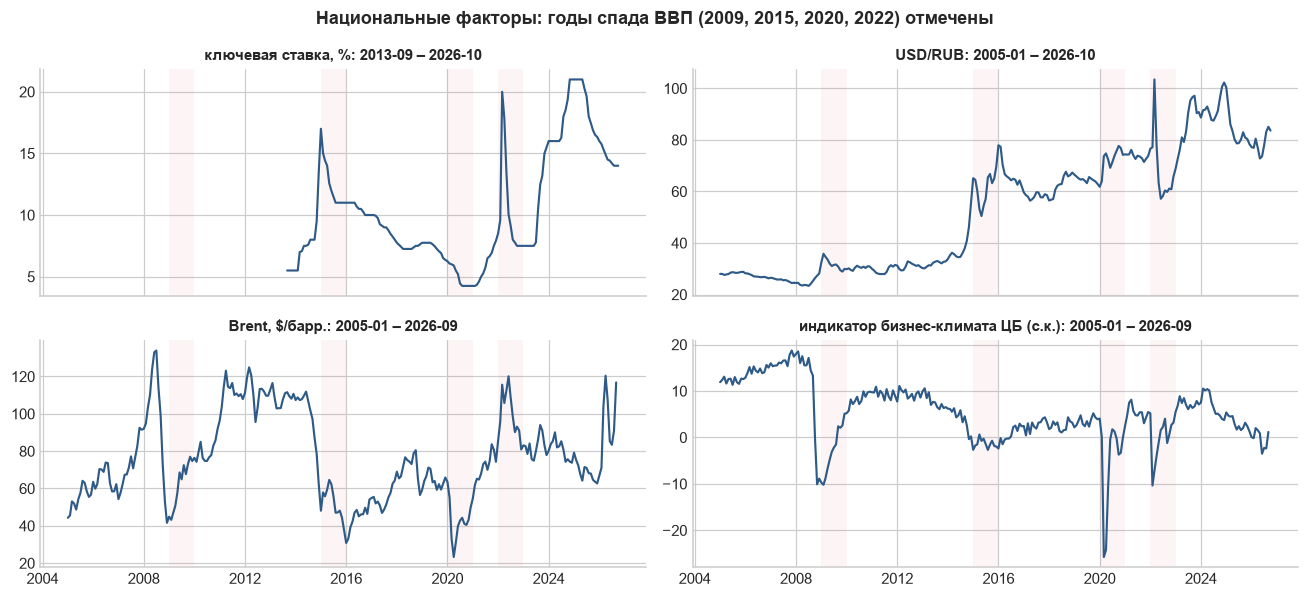

Национальных рядов: 126 , из них начинаются позже 2005 года: 12


,начало,конец
gdp_old_yoy_q,2005-03-01,2011-12-01
gdp_yoy_q,2012-03-01,2026-06-01
key_rate_avg,2013-09-01,2026-10-01
key_rate_eom,2013-09-01,2026-10-01
nonworking_paid_days,2010-01-01,2027-12-01
rf_ipp_energy_yoy,2015-01-01,2026-08-01
rf_ipp_manuf_yoy,2015-01-01,2026-08-01
rf_ipp_mining_yoy,2015-01-01,2026-08-01
rf_ipp_total_yoy,2015-01-01,2026-08-01
rf_ipp_water_yoy,2015-01-01,2026-08-01


In [32]:
N = D["features_national_monthly_wide"].copy()
N["date"] = pd.to_datetime(dict(year=N.year.astype(int), month=N.month.astype(int), day=1))
N = N[N.date >= "2005-01-01"].set_index("date")
series = {"key_rate_avg": "ключевая ставка, %", "usd_rub_avg": "USD/RUB", "wb_crude_oil_brent": "Brent, $/барр.",
          "ibk_total_sa": "индикатор бизнес-климата ЦБ (с.к.)"}
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for ax, (c, lab) in zip(axes.ravel(), series.items()):
    s = N[c].dropna()
    ax.plot(s.index, s, color=C_MAIN, lw=1.4)
    for y in [2009, 2015, 2020, 2022]:
        ax.axvspan(pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y}-12-31"), color=C_ACC, alpha=0.06, lw=0)
    ax.set_title(f"{lab}: {s.index.min():%Y-%m} – {s.index.max():%Y-%m}", fontsize=10)
fig.suptitle("Национальные факторы: годы спада ВВП (2009, 2015, 2020, 2022) отмечены", fontweight="bold")
plt.tight_layout()
plt.show()

nat_cov = pd.DataFrame({c: [N[c].first_valid_index(), N[c].last_valid_index()] for c in N.columns if c not in ("year", "month")},
                       index=["начало", "конец"]).T
nat_cov["начало"] = pd.to_datetime(nat_cov["начало"])
print("Национальных рядов:", len(nat_cov), ", из них начинаются позже 2005 года:",
      (nat_cov["начало"] > "2005-01-01").sum())
nat_cov[nat_cov["начало"] > "2005-01-01"]

Из 126 национальных рядов 12 начинаются позже 2005 года. Самое неудобное для обучения, что ключевая ставка есть только с сентября 2013 года. До этого нужна ставка рефинансирования или ставка межбанковского рынка, иначе денежные условия в обучающем окне не описать. Квартальный ВВП тоже меняет методологию (до 2011 года старый ряд, с 2012 года новый), ИПП РФ в ОКВЭД2 начинается с 2015 года.

## 9. Итоги

### 9.1. Ответы на вопросы EDA

**1. Как устроена цель.** С 2005 года ИФО ВРП есть у 80–85 единиц из 85, в обучающем окне 985 наблюдений «регион-год», на валидации 425. Ряды ОКВЭД-2007 (до 2016 года) и ОКВЭД2 (с 2017 года) не пересекаются ни в одном году, склейка механическая. Пропуски объясняются составом выборки: Крым и Севастополь появляются в 2015 году, Тюменская и Архангельская области без АО в 2012 году. 21 ноль в источнике означает пропуск (автономные округа за 1997–2000 годы, Чечня за 1997–2005 годы), их я заменил на NaN.

Распределение почти симметричное, но с тяжёлыми хвостами: стандартное отклонение 5,4 п.п. на обучении, 3,4 на валидации, 5 на тесте. Крайние значения дают малые экономики с одним-двумя крупными проектами: Ненецкий АО, Чукотка, Сахалин, Ингушетия, Еврейская АО. Общий шок года объясняет 41% разброса на обучении и 29% на валидации, постоянные различия регионов сверх случайности всего 3% и 6%, остальное (около половины) приходится на отклонения конкретного региона в конкретном году. Эти отклонения почти не повторяются на следующий год (корреляция 0,14–0,16).

**2. Какие признаки есть в каком периоде.** В обучающем окне 2005–2016 годов на 90% и больше заполнены только 24 из 119 региональных месячных признаков: ИПП в ОКВЭД-2007 и ИПЦ. Кредитов Банка России в обучении нет совсем (ряды начинаются в 2019 году), налоги помесячно есть только с 2011 года, торговля и строительство с 2009 года, ввод жилья с 2012 года. На валидации полных признаков 81, на тесте 99. Из национальных рядов главная проблема в ключевой ставке: она есть только с сентября 2013 года. Меньше всего данных у Крыма и Севастополя (заполненность 74–76%) и у Тюменской и Архангельской области (90%). Общие для всех регионов пропуски, есть в 33 признаках: налоги нарастающим итогом за 2007–2010 годы даны только на декабрь, у месячных налогов нет января–марта 2024 года.

**3. Нули, выбросы и разрывы методологии.** Нули в индексах означают пропуски, а не нулевой выпуск: в строительстве с начала года их 212, всего в декабрьских значениях их 4377. В строительстве и добыче от 3 до 12% месячных значений лежат вне диапазона [50, 200], у цен и зарплат коридор узкий. ИПП в ОКВЭД-2007 и ОКВЭД2 на границе 2015–2016 годов расходятся: помесячно корреляция 0,54–0,67, по годам 0,57. Месячные ряды сильно сезонны (в декабре 12,8% годового объёма строительства и 19% ввода жилья), поэтому в работу идут индексы к прошлому году и с начала года.

**4. Какие ряды связаны с ростом ВРП и держится ли связь.** Без вычитания года корреляции обманчивы: розница даёт 0,56 по панели и только 0,25 внутри года, ВВП 0,62 по панели и ноль внутри года. Внутри года сильнее и стабильнее всех ИПП: 0,46 на обучении и 0,48 на валидации, по рангам 0,46 и 0,5. На валидации рядом с ним выпуск по базовым видам (0,49, по рангам 0,55), но этот ряд есть только с 2018 года. Связь держится у добычи и обработки (0,23–0,28), а у энергетики, опта, реальной зарплаты и налогов она тоже держится, но слабая (0,12–0,19). Ослабевают или исчезают при переходе к валидации строительство (с 0,23 до 0,10), ввод жилья (с 0,26 до −0,04), НДФЛ (с 0,31 до 0,22), сельское хозяйство (с 0,21 до 0,13) и розница (с 0,25 до 0,18). У платных услуг, розницы и ввода жилья ранговая корреляция заметно ниже обычной, значит, связь там держится на нескольких крайних значениях. ИПЦ с ростом ВРП не связан. Даже ИПП объясняет около четверти разброса внутри года.

**5. Зависимости роста ВРП с другими признаками.** Сильнее всего рост регионов связан с ВВП: корреляция медианы регионов с ВВП 0,97. Сумма ВРП при этом не равна ВВП и во всех четырёх годах спада (2009, 2015, 2020, 2022) падала слабее на 1 п.п. в среднем. Связь с соседями слабая и меняется по годам: индекс Морана значим в 2006–2011, 2013–2014 и 2020–2023 годах (0,12–0,32), в 2015–2019 годах связи нет, корреляция отклонений у соседей по границе 0,12. Реакция на шоки зависит от структуры экономики: в 2022 году сырьевые и промышленные регионы росли медленнее прочих (−0,3% и −0,5% против +1,8%), в 2023–2024 годах вперёд ушли промышленные.

### 9.2. Главное для моделей

- Правило «рост региона равен росту ВВП» даёт на валидации RMSE 3,04 п.п. В момент backcasting (когда модель в момент года t предсказывает ВРП по году t-1), когда ВВП опубликован, модель должна быть заметно точнее RMSE 3,04 п.п. В момент nowcasting года t годовую компоненту придётся оценивать модели самой по региональным признакам.
- Сигнал о регионе приходится брать из данных текущего года. Прошлое региона почти ничего не говорит, эффекты регионов малы и плохо переносятся между периодами, их стоит сильно сжимать к нулю с помощью случайных эффектов или l2-регуляризации.
- Основу признаков составит промышленность. Остальные ряды либо слабо связаны с ростом ВРП, либо не держат связь на валидации, либо отсутствуют в обучающем окне.
- Ошибка будет выше в кризисные годы: разброс между регионами в 2009 году был 6,7 п.п., в 2022–2023 годах 4,6 п.п., в спокойные годы около 2,5 п.п.
- Метрику надо считать и без весов, и с весами по ВРП, потому что без весов малые волатильные регионы перекрывают всё остальное.
- При обучении нужно попробовать робастную функцию потерь и сравнить с MSE на валидации.
- Перед построением сделать предобработку данных. Нули в индексах превратить в пропуски, шкалу индекса в log(индекс/100), добавить в признаки индикатор классификации ОКВЭД.

### 9.3. Что обсудить

- Начало обучающего окна: 2005 год, 2011–2012 годы либо две версии моделей (длинная на ИПП и ИПЦ, короткая на всех рядах). -- я за этот вариант, мы с Антоном можем делать разные модели и потом сравнить (Гурам)

## 10. Список фичей в результате EDA.

#### Таргет

- `grp_okved1_yoy` - ИФО ВРП, % к предыдущему году, ОКВЭД-2007 (до 2016 года)
- `grp_yoy` - ИФО ВРП, % к предыдущему году, ОКВЭД2 (с 2017 года)

#### Национальные

- `gdp_yoy_y` - рост ВВП России за год, % (с 2012 года)
- `gdp_old_yoy_y` - рост ВВП России за год, старая методология (до 2011 года)
- `gdp_yoy_q` - рост ВВП России за квартал, % к кварталу прошлого года (с 2012 года)
- `gdp_old_yoy_q` - рост ВВП России за квартал, старая методология (2005–2011)
- `rf_ipp_total_yoy` - ИПП РФ, % к месяцу прошлого года, ОКВЭД2
- `rf_ipp_mining_yoy` - ИПП РФ, добыча полезных ископаемых
- `rf_ipp_manuf_yoy` - ИПП РФ, обрабатывающие производства
- `rf_ipp_energy_yoy` - ИПП РФ, обеспечение электроэнергией, газом и паром
- `rf_ipp_mining_okved1_yoy`, `rf_ipp_manuf_okved1_yoy`, `rf_ipp_energy_okved1_yoy` - то же по ОКВЭД-2007 (до 2016 года)
- `rf_retail_yoy` - оборот розничной торговли РФ, % к месяцу прошлого года
- `ibk_total_sa` - индикатор бизнес-климата Банка России, сезонно скорректированный

#### Региональные основные

- `ipp_total_ytd_yoy` - ИПП региона с начала года, % к тому же периоду прошлого года, ОКВЭД2
- `ipp_total_okved1_ytd_yoy` - то же, ОКВЭД-2007 (до 2016 года)
- `ipp_mining_ytd_yoy` - ИПП, добыча полезных ископаемых, с начала года, ОКВЭД2
- `ipp_mining_okved1_ytd_yoy` - то же, ОКВЭД-2007
- `ipp_manuf_ytd_yoy` - ИПП, обрабатывающие производства, с начала года, ОКВЭД2
- `ipp_manuf_okved1_ytd_yoy` - то же, ОКВЭД-2007
- `ipp_energy_ytd_yoy` - ИПП, электроэнергия, газ и пар, с начала года, ОКВЭД2
- `ipp_energy_okved1_ytd_yoy` - то же, ОКВЭД-2007
- `ipp_water_ytd_yoy` - ИПП, водоснабжение и утилизация отходов, с начала года (только ОКВЭД2)

#### Региональные дополнительные

- `tax_ndfl_ytd` - поступления НДФЛ нарастающим итогом, руб. (в модели как реальный рост к прошлому году)
- `tax_total_ytd` - все налоговые поступления нарастающим итогом, руб. (в модели как реальный рост)
- `wholesale_ytd_yoy` - ИФО оборота оптовой торговли с начала года (с 2017 года)
- `wholesale_yoy` - ИФО оборота оптовой торговли, месяц к месяцу прошлого года (до 2017 года, в среднем за год)
- `wage_real_ytd_yoy` - реальная начисленная зарплата с начала года, % к тому же периоду прошлого года
- `cpi_dec` - ИПЦ региона к декабрю прошлого года, % (как дефлятор рядов с единицей измерения рубли)

#### Региональные для короткой версии модели

- `bvd_ytd_yoy` - индекс выпуска по базовым видам деятельности с начала года (с 2018 года)
- `loans_corp_debt` - задолженность юрлиц и ИП по кредитам, руб. (с 2019 года, в модели как реальный рост)
- `constr_ytd_yoy` - ИФО работ «Строительство» с начала года, ОКВЭД2 (с 2016 года)
- `constr_okved1_ytd_yoy` - ИФО работ по договорам строительного подряда с начала года, ОКВЭД-2007 (2009–2015)
- `agri_y_yoy` - индекс производства сельского хозяйства за год, % (с 2017 года)
- `agri_old_y_yoy` - то же, старый ряд (до 2016 года)
- `retail_y_yoy` - ИФО оборота розничной торговли за год, %
- `services_ytd_yoy` - ИФО платных услуг населению с начала года (с 2017 года)

#### Структурные

- `grp_share_dobycha_poleznykh_iskopaemykh` - доля добычи полезных ископаемых в ВРП, %, ОКВЭД2
- `grp_share_obrabatyvayushchie_proizvodstva` - доля обрабатывающих производств в ВРП, %
- `grp_share_obespechenie_elektricheskoy_energiey_gaz` - доля энергетики в ВРП, %
- `grp_share_vodosnabzhenie_vodootvedenie_organizatsi` - доля водоснабжения и утилизации отходов в ВРП, %
- `grp_share_stroitelstvo` - доля строительства в ВРП, %
- `grp_share_selskoe_lesnoe_khozyaystvo_okhota_rybolo` - доля сельского хозяйства в ВРП, %
- `grp_share_torgovlya_optovaya_i_roznichnaya_remont_` - доля торговли в ВРП, %
- `grp_share_okved1_razdel_*` - те же доли по разделам ОКВЭД-2007 (2004–2015)